# Контрольная работа №1: База знаний экосистемы библиотек PyTorch
## Проектирование онтологии, построение графа знаний, текстовый корпус, SHACL-валидация и вывод OWL 2 RL

**Дисциплина:** Семантические технологии  
**Предметная область:** Открытые Python-библиотеки глубокого обучения экосистемы PyTorch (52 сущности класса `wd:Q29642950`, связанные через `wdt:P1547` с `wd:Q47509047` и обладающие репозиторием `wdt:P1324`).

### Содержание отчета:
1. **Глава 1. Выбор и верификация предметной области (Задание 1)**
   - 1.0. Выгрузка данных из Wikidata SPARQL endpoint
   - 1.1. Свойства домена
   - 1.2. Проверка домена по критериям контрольной работы
   - 1.3. Обязательная статистика домена
2. **Глава 2. Формулировка 12 вопросов к базе знаний (Задание 2)**
   - 2.1. Инициализация графа знаний и текстового корпуса
   - 2.2. Вопросы к графу знаний (Вопросы 1–6)
   - 2.3. Вопросы к текстовому корпусу (Вопросы 7–10)
   - 2.4. Комбинированные вопросы (Вопросы 11–12)
3. **Глава 3. Разработка онтологии предметной области в Protégé (Задание 3)**
   - 3.1. Моделирование онтологии и архитектура классов
   - 3.2. Верификация сборки онтологии `ontology.ttl`
4. **Глава 4. Построение, статистика и верификация графа знаний (Задание 4)**
   - 4.1. Сборка и верификация графа знаний `knowledge_graph.ttl`
   - 4.2. Верификация наличия `owl:sameAs` для сущностей домена
   - 4.3. Статистика графа знаний: тройки, сущности, разбивка по классам и свойствам
   - 4.4. Верификация графа знаний целевыми SPARQL-запросами
   - 4.5. Итоги выполнения заданий 3 и 4
5. **Глава 5. Сбор текстовой информации по сущностям (Задание 5)**
   - 5.1. Источники и структура текстового корпуса
   - 5.2. Источник текстовой информации для каждой сущности
6. **Глава 6. Проверка данных (SHACL) и логический вывод (OWL 2 RL) (Задание 6)**
   - 6.1. Ограничения целостности SHACL
   - 6.2. Результат pyshacl на исходных данных
   - 6.3. Контрольный эксперимент: выявление пяти типов нарушений
   - 6.4. Решения по каждому типу нарушения и повторная проверка
   - 6.5. Дедуктивный логический вывод OWL 2 RL
   - 6.6. Анализ добавленных троек и механизмов вывода
   - 6.7. Итоговые проверки выполнения заданий 5 и 6
7. **Глава 7. Сводная таблица итоговых показателей проекта**


In [1]:
# Инициализация рабочей среды и привязка к корневой директории проекта
import os
import sys
from pathlib import Path

# Поиск корневой директории проекта с графом знаний и онтологией
project = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'knowledge_graph.ttl').is_file() and (p / 'data/corpus.jsonl').is_file()
)
os.chdir(project)
print(f"Корень проекта: {project.resolve()}")
assert (project / 'knowledge_graph.ttl').is_file(), "Файл knowledge_graph.ttl не найден!"
assert (project / 'ontology.ttl').is_file(), "Файл ontology.ttl не найден!"
assert (project / 'shapes.shacl.ttl').is_file(), "Файл shapes.shacl.ttl не найден!"


Корень проекта: C:\Users\jack_\MAIN\ВУЗ\СемТех Блохин\КР


# Глава 1. Выбор и верификация предметной области (Задание 1)

## 1.0. Скачивание и обработка

Выгрузка данных из Wikidata SPARQL endpoint для открытых библиотек Python экосистемы PyTorch и их локальное сохранение.

In [2]:
import requests
import json
import os

url = "https://query.wikidata.org/sparql"
headers = {"User-Agent": "DomainVerification/1.0 (test@example.org)"}

query_entities = """
SELECT DISTINCT ?item ?itemLabel ?repo WHERE {
  ?item wdt:P31 wd:Q29642950 ;
        wdt:P1547 wd:Q47509047 ;
        wdt:P1324 ?repo .
  SERVICE wikibase:label { bd:serviceParam wikibase:language "en,ru,mul,da". }
}
ORDER BY ?itemLabel
"""

response = requests.get(url, params={"query": query_entities, "format": "json"}, headers=headers)
data = response.json()
bindings = data["results"]["bindings"]

entities_dict = {}
for b in bindings:
    qid = b["item"]["value"].split("/")[-1]
    name = b["itemLabel"]["value"]
    repo = b["repo"]["value"]
    if name.startswith("Q") and name[1:].isdigit() and repo:
        name = repo.rstrip("/").split("/")[-1]
    if qid not in entities_dict:
        entities_dict[qid] = {
            "qid": qid,
            "name": name,
            "repo": repo
        }
entities = list(entities_dict.values())

os.makedirs("data", exist_ok=True)
filepath = "data/task1_entities.json"
with open(filepath, "w", encoding="utf-8") as f:
    json.dump(entities, f, ensure_ascii=False, indent=2)

file_size = os.path.getsize(filepath)
with open(filepath, "r", encoding="utf-8") as f:
    content = f.read()

print("Число выгруженных уникальных сущностей:", len(entities))
print("Файл сохранен:", filepath)
print("Размер файла в байтах:", file_size)
print("Число строк в файле:", len(content.splitlines()))

print("\nПервые 15 строк сохраненного файла:")
for line in content.splitlines()[:15]:
    print(line)

Число выгруженных уникальных сущностей: 52
Файл сохранен: data/task1_entities.json
Размер файла в байтах: 6174
Число строк в файле: 262

Первые 15 строк сохраненного файла:
[
  {
    "qid": "Q96631404",
    "name": "PyKEEN",
    "repo": "https://github.com/pykeen/pykeen"
  },
  {
    "qid": "Q85847011",
    "name": "PyTorch Lightning",
    "repo": "https://github.com/Lightning-AI/lightning"
  },
  {
    "qid": "Q116908797",
    "name": "STonKGs",
    "repo": "https://github.com/stonkgs/stonkgs"


## 1.1. Свойства домена

### 1.1.1. Все свойства всех сущностей домена

In [3]:
query_all_props = """
SELECT DISTINCT ?item ?itemLabel ?p ?repo WHERE {
  ?item wdt:P31 wd:Q29642950 ;
        wdt:P1547 wd:Q47509047 ;
        wdt:P1324 ?repo ;
        ?p ?val .
  FILTER(STRSTARTS(STR(?p), "http://www.wikidata.org/prop/direct/"))
  SERVICE wikibase:label { bd:serviceParam wikibase:language "en,ru,mul,da". }
}
"""

resp_all_props = requests.get(url, params={"query": query_all_props, "format": "json"}, headers=headers)
all_prop_rows = resp_all_props.json()["results"]["bindings"]

entity_props = {}
all_unique_pids = set()

for r in all_prop_rows:
    qid = r["item"]["value"].split("/")[-1]
    name = r["itemLabel"]["value"]
    repo = r["repo"]["value"]
    if name.startswith("Q") and name[1:].isdigit() and repo:
        name = repo.rstrip("/").split("/")[-1]
    pid = r["p"]["value"].split("/")[-1]
    all_unique_pids.add(pid)
    if qid not in entity_props:
        entity_props[qid] = {"name": name, "repo": repo, "props": set()}
    entity_props[qid]["props"].add(pid)

print("Всего сущностей в обработке:", len(entity_props))
print("Всего различных предикатов найдено в домене:", len(all_unique_pids))
print("Список всех уникальных предикатов:", sorted(list(all_unique_pids)))

Всего сущностей в обработке: 52
Всего различных предикатов найдено в домене: 22
Список всех уникальных предикатов: ['P1324', 'P1343', 'P1401', 'P1451', 'P1547', 'P178', 'P2037', 'P2078', 'P2671', 'P275', 'P277', 'P2888', 'P31', 'P3454', 'P348', 'P366', 'P4162', 'P4901', 'P5568', 'P6216', 'P6251', 'P856']


### 1.1.2. Распределение сущностей по числу свойств

In [4]:
counts = [len(data["props"]) for qid, data in entity_props.items()]
min_props = min(counts)
max_props = max(counts)
avg_props = sum(counts) / len(counts)

freq = {}
for c in sorted(counts):
    freq[c] = freq.get(c, 0) + 1

print("Минимальное число свойств у сущности:", min_props)
print("Максимальное число свойств у сущности:", max_props)
print("Среднее число свойств у сущности:", round(avg_props, 2))

print("\nРаспределение сущностей по числу свойств:")
print(f"{'Число свойств':15} | {'Число сущностей':15} | Доля от выборки")
print("-" * 50)
for prop_c, ent_c in sorted(freq.items()):
    share = (ent_c / len(entity_props)) * 100
    print(f"{prop_c:15} | {ent_c:15} | {share:6.2f}%")

Минимальное число свойств у сущности: 5
Максимальное число свойств у сущности: 17
Среднее число свойств у сущности: 7.85

Распределение сущностей по числу свойств:
Число свойств   | Число сущностей | Доля от выборки
--------------------------------------------------
              5 |               2 |   3.85%
              6 |              13 |  25.00%
              7 |              11 |  21.15%
              8 |              16 |  30.77%
              9 |               2 |   3.85%
             10 |               1 |   1.92%
             11 |               2 |   3.85%
             12 |               4 |   7.69%
             17 |               1 |   1.92%


### 1.1.3. Сущности с экстремальным числом свойств (минимум и максимум)

In [5]:
min_entities = [item for item in entity_props.items() if len(item[1]["props"]) == min_props]
print("Сущности с минимальным числом свойств (" + str(min_props) + "):")
for qid, data in min_entities:
    print(qid, "|", data["name"], "| свойства:", sorted(list(data["props"])))

max_entities = [item for item in entity_props.items() if len(item[1]["props"]) == max_props]
print("\nСущности с максимальным числом свойств (" + str(max_props) + "):")
for qid, data in max_entities:
    print(qid, "|", data["name"], "| свойства:", sorted(list(data["props"])))

Сущности с минимальным числом свойств (5):
Q120733208 | flexgen | свойства: ['P1324', 'P1547', 'P275', 'P31', 'P5568']
Q120550396 | pytorch-wavelets | свойства: ['P1324', 'P1547', 'P31', 'P348', 'P5568']

Сущности с максимальным числом свойств (17):
Q96631404 | PyKEEN | свойства: ['P1324', 'P1343', 'P1401', 'P1451', 'P1547', 'P178', 'P2037', 'P275', 'P277', 'P31', 'P348', 'P366', 'P4901', 'P5568', 'P6216', 'P6251', 'P856']


### 1.1.4. Полный список всех сущностей, ранжированных по количеству свойств

In [6]:
ranked_entities = sorted(entity_props.items(), key=lambda x: (len(x[1]["props"]), x[1]["name"]))

print(f"{'№':2} | {'QID':12} | {'Название':26} | {'Число':5} | Свойства")
print("-" * 80)
for idx, (qid, data) in enumerate(ranked_entities, 1):
    props_str = ", ".join(sorted(list(data["props"])))
    print(f"{idx:2} | {qid:12} | {data['name'][:26]:26} | {len(data['props']):5} | {props_str}")

№  | QID          | Название                   | Число | Свойства
--------------------------------------------------------------------------------
 1 | Q120733208   | flexgen                    |     5 | P1324, P1547, P275, P31, P5568
 2 | Q120550396   | pytorch-wavelets           |     5 | P1324, P1547, P31, P348, P5568
 3 | Q107382224   | bert-score                 |     6 | P1324, P1547, P275, P31, P348, P5568
 4 | Q120549792   | clean-fid                  |     6 | P1324, P1547, P275, P31, P5568, P856
 5 | Q107382238   | fairseq                    |     6 | P1324, P1547, P275, P31, P348, P5568
 6 | Q120733123   | fschat                     |     6 | P1324, P1547, P275, P31, P348, P5568
 7 | Q120549808   | gfpgan                     |     6 | P1324, P1547, P31, P348, P4162, P5568
 8 | Q120634941   | hummingbird-ml             |     6 | P1324, P1547, P275, P31, P348, P5568
 9 | Q120550360   | open-clip-torch            |     6 | P1324, P1547, P31, P348, P4162, P5568
10 | Q120550386  

## 1.2. Проверка домена по критериям контрольной работы


(макс. 1 балл) Выбрать домен и зафиксировать его в общей таблице. Домены не должны пересекаться в рамках учебной группы. Требования к домену:
- домен содержит 30–60 сущностей одного основного класса в Wikidata;
- у большинства сущностей заполнены хотя бы 5 свойств, среди них даты и числа;
- хотя бы одно свойство имеет квалификатор времени (руководитель с датами, показатель с годом);
- по большинству сущностей есть текстовое описание (Википедия, официальный сайт, энциклопедия и т.п.).

### 1.2.1. Домен содержит 30–60 сущностей одного основного класса в Wikidata

In [7]:
total_entities_count = len(entities)
is_size_valid = 30 <= total_entities_count <= 60

print("Основной класс в Wikidata: wd:Q29642950 (Python library)")
print("Число сущностей выборки:", total_entities_count)
print("Диапазон требования: от 30 до 60")
print("Критерий размера выборки выполнен:", is_size_valid)

print("\nПервые 5 сущностей выборки:")
for e in entities[:5]:
    print(e["qid"], "|", e["name"], "|", e["repo"])

Основной класс в Wikidata: wd:Q29642950 (Python library)
Число сущностей выборки: 52
Диапазон требования: от 30 до 60
Критерий размера выборки выполнен: True

Первые 5 сущностей выборки:
Q96631404 | PyKEEN | https://github.com/pykeen/pykeen
Q85847011 | PyTorch Lightning | https://github.com/Lightning-AI/lightning
Q116908797 | STonKGs | https://github.com/stonkgs/stonkgs
Q120550372 | Stanza | https://github.com/stanfordnlp/stanza
Q116908792 | accelerate | https://github.com/huggingface/accelerate


### 1.2.2. Заполнены хотя бы 5 свойств

In [8]:
ge_5_entities = [qid for qid, data in entity_props.items() if len(data["props"]) >= 5]
ge_5_share = (len(ge_5_entities) / len(entity_props)) * 100

print("Всего сущностей проверено:", len(entity_props))
print("Минимальное число свойств у сущности:", min_props)
print("Сущностей с не менее чем 5 свойствами:", len(ge_5_entities))
print("Доля сущностей с не менее чем 5 свойствами:", str(round(ge_5_share, 2)) + "%")
print("Критерий большинства с не менее 5 свойствами выполнен:", ge_5_share >= 50.0)

Всего сущностей проверено: 52
Минимальное число свойств у сущности: 5
Сущностей с не менее чем 5 свойствами: 52
Доля сущностей с не менее чем 5 свойствами: 100.0%
Критерий большинства с не менее 5 свойствами выполнен: True


#### 1.2.2.1. Наличие дат

In [9]:
query_dates = """
SELECT ?item ?itemLabel ?version ?releaseDate WHERE {
  ?item wdt:P31 wd:Q29642950 ;
        wdt:P1547 wd:Q47509047 ;
        wdt:P1324 ?repo ;
        p:P348 ?statement .
  ?statement ps:P348 ?version ;
             pq:P577 ?releaseDate .
  SERVICE wikibase:label { bd:serviceParam wikibase:language "en,ru,mul,da". }
}
ORDER BY DESC(?releaseDate)
"""

resp_dates = requests.get(url, params={"query": query_dates, "format": "json"}, headers=headers)
date_rows = resp_dates.json()["results"]["bindings"]
entities_with_dates = set(r["item"]["value"] for r in date_rows)

print("Всего утверждений с датами релиза (pq:P577):", len(date_rows))
print("Число сущностей, содержащих даты:", len(entities_with_dates))
print("Доля сущностей с датами:", str(round(len(entities_with_dates) / len(entity_props) * 100, 2)) + "%")
print("Тип данных свойства даты:", date_rows[0]["releaseDate"]["datatype"])
print("Критерий наличия дат выполнен:", len(date_rows) > 0)

print("\nПримеры зафиксированных дат:")
for r in date_rows[:5]:
    print(r["itemLabel"]["value"], "| версия:", r["version"]["value"], "| дата:", r["releaseDate"]["value"])

Всего утверждений с датами релиза (pq:P577): 1720
Число сущностей, содержащих даты: 47
Доля сущностей с датами: 90.38%
Тип данных свойства даты: http://www.w3.org/2001/XMLSchema#dateTime
Критерий наличия дат выполнен: True

Примеры зафиксированных дат:
open-clip-torch | версия: 4.2.2 | дата: 2026-11-10T00:00:00Z
pytorch-pretrained-bert | версия: 5.22.2 | дата: 2026-11-06T00:00:00Z
pytorch-transformers | версия: 5.22.2 | дата: 2026-11-06T00:00:00Z
open-clip-torch | версия: 4.2.1 | дата: 2026-11-06T00:00:00Z
timm | версия: 1.0.31 | дата: 2026-11-03T00:00:00Z


#### 1.2.2.2. Наличие чисел

In [10]:
query_numbers = """
SELECT ?item ?itemLabel (COUNT(DISTINCT ?statement) AS ?versionCount) WHERE {
  ?item wdt:P31 wd:Q29642950 ;
        wdt:P1547 wd:Q47509047 ;
        wdt:P1324 ?repo ;
        p:P348 ?statement .
  ?statement ps:P348 ?version .
  SERVICE wikibase:label { bd:serviceParam wikibase:language "en,ru,mul,da". }
}
GROUP BY ?item ?itemLabel
ORDER BY DESC(?versionCount)
"""

resp_numbers = requests.get(url, params={"query": query_numbers, "format": "json"}, headers=headers)
number_rows = resp_numbers.json()["results"]["bindings"]

numeric_records = []
for r in number_rows:
    numeric_records.append({
        "qid": r["item"]["value"].split("/")[-1],
        "name": r["itemLabel"]["value"],
        "count": int(r["versionCount"]["value"]),
        "datatype": r["versionCount"].get("datatype", "")
    })

num_values = [rec["count"] for rec in numeric_records]

print("Число сущностей с числовым свойством количества версий:", len(numeric_records))
print("Доля сущностей с числовыми значениями:", str(round(len(numeric_records) / len(entity_props) * 100, 2)) + "%")
print("Общее количество релизов (сумма чисел):", sum(num_values))
print("Минимальное число версий:", min(num_values))
print("Максимальное число версий:", max(num_values))
print("Среднее число версий на библиотеку:", round(sum(num_values) / len(num_values), 2))
print("Тип данных числового параметра:", numeric_records[0]["datatype"])
print("Критерий наличия чисел выполнен:", len(numeric_records) > 0)

print("\nПримеры числовых значений (топ-5 библиотек по числу версий):")
for rec in numeric_records[:5]:
    type_short = rec["datatype"].split("#")[-1]
    print(rec["qid"], "|", rec["name"], "| число версий:", rec["count"], "| xsd:" + type_short)

Число сущностей с числовым свойством количества версий: 47
Доля сущностей с числовыми значениями: 90.38%
Общее количество релизов (сумма чисел): 1616
Минимальное число версий: 1
Максимальное число версий: 242
Среднее число версий на библиотеку: 34.38
Тип данных числового параметра: http://www.w3.org/2001/XMLSchema#integer
Критерий наличия чисел выполнен: True

Примеры числовых значений (топ-5 библиотек по числу версий):
Q107385500 | pytorch-pretrained-bert | число версий: 242 | xsd:integer
Q107385836 | pytorch-transformers | число версий: 242 | xsd:integer
Q85847011 | PyTorch Lightning | число версий: 104 | xsd:integer
Q116908792 | accelerate | число версий: 67 | xsd:integer
Q107381756 | torchmetrics | число версий: 63 | xsd:integer


### 1.2.3. Свойство с квалификатором времени

In [11]:
print("Свойство, содержащее квалификатор времени: P348 (версия программы)")
print("Квалификатор времени: pq:P577 (дата публикации)")
print("Всего утверждений с данным квалификатором времени:", len(date_rows))
print("Число сущностей, у которых заполнен данный квалификатор времени:", len(entities_with_dates))
print("Доля сущностей с квалификатором времени:", str(round(len(entities_with_dates) / len(entity_props) * 100, 2)) + "%")
print("Критерий наличия квалификатора времени выполнен:", len(date_rows) > 0)

print("\nПервые 5 утверждений с квалификатором времени:")
for r in date_rows[:5]:
    print(r["itemLabel"]["value"], "| версия:", r["version"]["value"], "| дата публикации (pq:P577):", r["releaseDate"]["value"])

Свойство, содержащее квалификатор времени: P348 (версия программы)
Квалификатор времени: pq:P577 (дата публикации)
Всего утверждений с данным квалификатором времени: 1720
Число сущностей, у которых заполнен данный квалификатор времени: 47
Доля сущностей с квалификатором времени: 90.38%
Критерий наличия квалификатора времени выполнен: True

Первые 5 утверждений с квалификатором времени:
open-clip-torch | версия: 4.2.2 | дата публикации (pq:P577): 2026-11-10T00:00:00Z
pytorch-pretrained-bert | версия: 5.22.2 | дата публикации (pq:P577): 2026-11-06T00:00:00Z
pytorch-transformers | версия: 5.22.2 | дата публикации (pq:P577): 2026-11-06T00:00:00Z
open-clip-torch | версия: 4.2.1 | дата публикации (pq:P577): 2026-11-06T00:00:00Z
timm | версия: 1.0.31 | дата публикации (pq:P577): 2026-11-03T00:00:00Z


### 1.2.4. Текстовые описания

In [12]:
corpus_path = "data/corpus.jsonl"
with open(corpus_path, "r", encoding="utf-8") as f:
    corpus_docs = [json.loads(line) for line in f]

corpus_lengths = [len(d["text"]) for d in corpus_docs]

print("Файл текстового корпуса:", corpus_path)
print("Размер файла на диске в байтах:", os.path.getsize(corpus_path))
print("Число документов в корпусе:", len(corpus_docs))
print("Охват выборки текстовыми описаниями:", str(round(len(corpus_docs) / len(entity_props) * 100, 2)) + "%")
print("Минимальная длина текста в символах:", min(corpus_lengths))
print("Максимальная длина текста в символах:", max(corpus_lengths))
print("Средняя длина текста в символах:", round(sum(corpus_lengths) / len(corpus_lengths), 1))
print("Критерий наличия текстовых описаний выполнен:", len(corpus_docs) == len(entity_props))

print("\nПример первого документа корпуса:")
doc0 = corpus_docs[0]
print("QID:", doc0["id"])
print("Название:", doc0["name"])
print("Источник:", doc0["source_url"])
print("Длина текста:", len(doc0["text"]))
print("Фрагмент текста:\n", doc0["text"][:180])

Файл текстового корпуса: data/corpus.jsonl
Размер файла на диске в байтах: 216836
Число документов в корпусе: 52
Охват выборки текстовыми описаниями: 100.0%
Минимальная длина текста в символах: 2069
Максимальная длина текста в символах: 4000
Средняя длина текста в символах: 3885.9
Критерий наличия текстовых описаний выполнен: True

Пример первого документа корпуса:
QID: Q96631404
Название: PyKEEN
Источник: https://raw.githubusercontent.com/pykeen/pykeen/master/README.md
Длина текста: 4000
Фрагмент текста:
 <p align="center">
  <img src="docs/source/logo.png" height="150">
</p>

<h1 align="center">
  PyKEEN
</h1>

<p align="center">
  <a href="https://github.com/pykeen/pykeen/actions/


## 1.3. Обязательная статистика домена


После выбора домена вы должны проверить его на требования, описанные выше. Для этого требуется SPARQL-запросом к Wikidata посчитать сущности основного класса и заполненность их свойств. В отчете указывается:
- статистика по основным свойствам (доля сущностей, у которых это свойство заполнено)
- набор свойств, имеющих квалификатор времени
- для каждой сущности – ссылка на источник текстовой информации

### 1.3.1. Статистика по основным свойствам

In [13]:
prop_labels = {
    "P1324": "Репозиторий с исходным кодом",
    "P31": "Экземпляр класса",
    "P1547": "Зависимость от программного обеспечения",
    "P5568": "Тема GitHub",
    "P275": "Лицензия",
    "P348": "Версия программы",
    "P856": "Официальный сайт",
    "P4162": "Проект PyPI",
    "P6216": "Статус авторских прав",
    "P277": "Язык программирования",
    "P178": "Разработчик",
    "P1343": "Описано в источнике",
    "P1401": "Баг-трекер",
    "P366": "Использование",
    "P2078": "Руководство пользователя"
}

prop_counts = {}
for qid, data in entity_props.items():
    for pid in data["props"]:
        prop_counts[pid] = prop_counts.get(pid, 0) + 1

sorted_prop_counts = sorted(prop_counts.items(), key=lambda x: x[1], reverse=True)

print(f"{'Свойство':8} | {'Название':42} | {'Заполнено':9} | Доля от выборки")
print("-" * 75)
for pid, filled in sorted_prop_counts:
    label = prop_labels.get(pid, pid)
    ratio = (filled / len(entity_props)) * 100
    print(f"{pid:8} | {label:42} | {filled:2}/{len(entity_props)}    | {ratio:6.2f}%")

Свойство | Название                                   | Заполнено | Доля от выборки
---------------------------------------------------------------------------
P1324    | Репозиторий с исходным кодом               | 52/52    | 100.00%
P1547    | Зависимость от программного обеспечения    | 52/52    | 100.00%
P5568    | Тема GitHub                                | 52/52    | 100.00%
P31      | Экземпляр класса                           | 52/52    | 100.00%
P275     | Лицензия                                   | 49/52    |  94.23%
P348     | Версия программы                           | 47/52    |  90.38%
P856     | Официальный сайт                           | 33/52    |  63.46%
P4162    | Проект PyPI                                | 27/52    |  51.92%
P6216    | Статус авторских прав                      |  9/52    |  17.31%
P277     | Язык программирования                      |  8/52    |  15.38%
P178     | Разработчик                                |  7/52    |  13.46%
P1343    | Опис

### 1.3.2. Набор свойств, имеющих квалификатор времени

In [14]:
qual_props_info = [
    {
        "prop_id": "P348",
        "prop_label": "версия программы",
        "qual_id": "pq:P577",
        "qual_label": "дата публикации",
        "datatype": "xsd:dateTime",
        "statements_count": len(date_rows),
        "entities_count": len(entities_with_dates),
        "share": round(len(entities_with_dates) / len(entity_props) * 100, 2)
    }
]

print("Набор свойств, имеющих квалификатор времени в домене:")
for item in qual_props_info:
    print("Основное свойство:", item["prop_id"], "(" + item["prop_label"] + ")")
    print("Квалификатор времени:", item["qual_id"], "(" + item["qual_label"] + ")")
    print("Тип данных квалификатора:", item["datatype"])
    print("Число утверждений с квалификатором:", item["statements_count"])
    print("Охват сущностей:", str(item["entities_count"]) + "/" + str(len(entity_props)), "(" + str(item["share"]) + "%)")

Набор свойств, имеющих квалификатор времени в домене:
Основное свойство: P348 (версия программы)
Квалификатор времени: pq:P577 (дата публикации)
Тип данных квалификатора: xsd:dateTime
Число утверждений с квалификатором: 1720
Охват сущностей: 47/52 (90.38%)


### 1.3.3. Ссылки на источники текстовой информации

In [15]:
print(f"{'№':2} | {'QID':12} | {'Название библиотеки':26} | Ссылка на текстовый источник (README.md)")
print("-" * 105)
for idx, e in enumerate(entities, 1):
    raw_readme_url = e["repo"].replace("https://github.com/", "https://raw.githubusercontent.com/") + "/master/README.md"
    print(f"{idx:2} | {e['qid']:12} | {e['name'][:26]:26} | {raw_readme_url}")

№  | QID          | Название библиотеки        | Ссылка на текстовый источник (README.md)
---------------------------------------------------------------------------------------------------------
 1 | Q96631404    | PyKEEN                     | https://raw.githubusercontent.com/pykeen/pykeen/master/README.md
 2 | Q85847011    | PyTorch Lightning          | https://raw.githubusercontent.com/Lightning-AI/lightning/master/README.md
 3 | Q116908797   | STonKGs                    | https://raw.githubusercontent.com/stonkgs/stonkgs/master/README.md
 4 | Q120550372   | Stanza                     | https://raw.githubusercontent.com/stanfordnlp/stanza/master/README.md
 5 | Q116908792   | accelerate                 | https://raw.githubusercontent.com/huggingface/accelerate/master/README.md
 6 | Q107382302   | allennlp                   | https://raw.githubusercontent.com/allenai/allennlp/master/README.md
 7 | Q107382376   | attacut                    | https://raw.githubusercontent.com/PyThaiNLP

# Глава 2. Формулировка 12 вопросов к базе знаний (Задание 2)


Контрольная работа по дисциплине «Семантические технологии». Предметная область — 52 библиотеки экосистемы PyTorch. Эталонные ответы относятся к графу knowledge_graph.ttl и корпусу data/corpus.jsonl из текущего снимка WIKIBASE.

[Условие контрольной работы](https://docs.google.com/document/d/1x7V7MV4sEXqoKcddzE-0TX4NfRwtbbWqO9DLcnxSyi8/edit?usp=sharing)

In [16]:
import json
from pathlib import Path

from rdflib import Graph

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knowledge_graph.ttl").is_file() and (p / "data/corpus.jsonl").is_file())
graph = Graph().parse(project / "knowledge_graph.ttl", format="turtle")
corpus = {}
with (project / "data" / "corpus.jsonl").open(encoding="utf-8") as file:
    for line in file:
        document = json.loads(line)
        corpus[document["id"]] = document


def run(query):
    result = graph.query(query)
    rows = list(result)
    print(*result.vars, sep=" | ")
    for row in rows:
        print(*row, sep=" | ")
    return rows


def check_quote(qid, quote):
    document = corpus[qid]
    assert quote in " ".join(document["text"].split())
    print(document["name"], qid)
    print(quote)

## Вопросы к графу знаний

### 1. У каких библиотек экосистемы PyTorch в графе зарегистрировано более 20 версий? Укажите названия и число версий.

**Тип.** Графовый — фильтр по числу

**Эталонный ответ.** В графе 23 такие записи.

| Библиотека | Число версий |
| --- | --- |
| pytorch-pretrained-bert | 242 |
| pytorch-transformers | 242 |
| PyTorch Lightning | 208 |
| accelerate | 67 |
| torchmetrics | 63 |
| open-clip-torch | 57 |
| Pyserini | 57 |
| botorch | 55 |
| rotary-embedding-torch | 53 |
| timm | 51 |
| allennlp | 47 |
| kornia | 42 |
| catalyst | 36 |
| peft | 36 |
| pyro-ppl | 36 |
| torchvision | 29 |
| gpytorch | 28 |
| flair | 27 |
| nerfacc | 26 |
| torchaudio | 24 |
| hummingbird-ml | 23 |
| PyKEEN | 22 |
| triton | 22 |

In [17]:
run("""
PREFIX pte: <http://example.org/pytorch-ecosystem#>
SELECT ?name ?count WHERE {
  ?library pte:libraryName ?name ; pte:versionCount ?count .
  FILTER(?count > 20)
}
ORDER BY DESC(?count) LCASE(STR(?name)) ?name
""");

name | count
pytorch-pretrained-bert | 242
pytorch-transformers | 242
PyTorch Lightning | 208
accelerate | 67
torchmetrics | 63
open-clip-torch | 57
Pyserini | 57
botorch | 55
rotary-embedding-torch | 53
timm | 51
allennlp | 47
kornia | 42
catalyst | 36
peft | 36
pyro-ppl | 36
torchvision | 29
gpytorch | 28
flair | 27
nerfacc | 26
torchaudio | 24
hummingbird-ml | 23
PyKEEN | 22
triton | 22


### 2. Сколько различных библиотек связано в графе с каждой лицензией?

**Тип.** Графовый — агрегация

**Эталонный ответ.**

| Лицензия | Число библиотек |
| --- | --- |
| лицензия MIT | 23 |
| Apache License 2.0 | 21 |
| модифицированная лицензия BSD | 6 |
| 2-пунктная лицензия BSD | 2 |
| Free To Use But Restricted | 1 |

В подсчёт также входит центральный узел PyTorch.

In [18]:
run("""
PREFIX pte: <http://example.org/pytorch-ecosystem#>
SELECT ?licenseName (COUNT(DISTINCT ?library) AS ?count) WHERE {
  ?library pte:hasLicense ?license .
  ?license pte:licenseName ?licenseName .
}
GROUP BY ?licenseName
ORDER BY DESC(?count) ?licenseName
""");

licenseName | count
лицензия MIT | 23
Apache License 2.0 | 21
модифицированная лицензия BSD | 6
2-пунктная лицензия BSD | 2
Free To Use But Restricted | 1


### 3. Какие пять библиотек занимают первые места по числу зарегистрированных в графе версий? При равенстве расположите их по названию.

**Тип.** Графовый — сортировка

**Эталонный ответ.**

| Библиотека | Число версий |
| --- | --- |
| pytorch-pretrained-bert | 242 |
| pytorch-transformers | 242 |
| PyTorch Lightning | 208 |
| accelerate | 67 |
| torchmetrics | 63 |

In [19]:
run("""
PREFIX pte: <http://example.org/pytorch-ecosystem#>
SELECT ?name ?count WHERE {
  ?library pte:libraryName ?name ; pte:versionCount ?count .
}
ORDER BY DESC(?count) LCASE(STR(?name)) ?name
LIMIT 5
""");

name | count
pytorch-pretrained-bert | 242
pytorch-transformers | 242
PyTorch Lightning | 208
accelerate | 67
torchmetrics | 63


### 4. Какие библиотеки компьютерного зрения зависят от PyTorch и распространяются по лицензии Apache License 2.0? Укажите ссылки на их репозитории.

**Тип.** Графовый — многошаговый переход

**Эталонный ответ.**

| Библиотека | Репозиторий |
| --- | --- |
| effdet | https://github.com/rwightman/efficientdet-pytorch |
| gfpgan | https://github.com/TencentARC/GFPGAN |
| kornia | https://github.com/kornia/kornia |
| timm | https://github.com/huggingface/pytorch-image-models |

Адрес получен переходом по двум рёбрам `hasRepository` и `repositoryURL`.

In [20]:
run("""
PREFIX pte: <http://example.org/pytorch-ecosystem#>
SELECT DISTINCT ?name ?repoUrl WHERE {
  ?library a pte:ComputerVisionLibrary ;
           pte:libraryName ?name ;
           pte:dependsOnSoftware pte:PyTorch ;
           pte:hasLicense pte:License_Apache_License_2_0 ;
           pte:hasRepository/pte:repositoryURL ?repoUrl .
}
ORDER BY ?name ?repoUrl
""");

name | repoUrl
effdet | https://github.com/rwightman/efficientdet-pytorch
gfpgan | https://github.com/TencentARC/GFPGAN
kornia | https://github.com/kornia/kornia
timm | https://github.com/huggingface/pytorch-image-models


### 5. Какие десять различных сочетаний библиотеки, номера версии и даты выпуска идут первыми по дате публикации в 2023 году? При равенстве дат отсортируйте по названию библиотеки и номеру версии как строке.

**Тип.** Графовый — временной квалификатор

**Эталонный ответ.**

| Библиотека | Версия | Дата (UTC) |
| --- | --- | --- |
| pyro-ppl | 1.8.4 | 2023-01-03 |
| gpytorch | 1.9.1 | 2023-01-04 |
| open-clip-torch | 2.9.2 | 2023-01-05 |
| botorch | 0.8.1 | 2023-01-06 |
| open-clip-torch | 2.9.3 | 2023-01-09 |
| PyTorch Lightning | 1.9.0 | 2023-01-17 |
| nerfacc | 0.3.3 | 2023-01-18 |
| open-clip-torch | 2.10.0 | 2023-01-23 |
| open-clip-torch | 2.10.1 | 2023-01-24 |
| pytorch-pretrained-bert | 4.26.0 | 2023-01-25 |

`releaseDate` хранит время публикации конкретной версии и соответствует квалификатору `pq:P577` исходного утверждения Wikidata о версии `p:P348`.

In [21]:
run("""
PREFIX pte: <http://example.org/pytorch-ecosystem#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
SELECT DISTINCT ?name ?version ?date WHERE {
  ?library pte:libraryName ?name ; pte:hasVersion ?release .
  ?release pte:versionIdentifier ?version ; pte:releaseDate ?date .
  FILTER(?date >= "2023-01-01T00:00:00Z"^^xsd:dateTime &&
         ?date < "2024-01-01T00:00:00Z"^^xsd:dateTime)
}
ORDER BY ?date ?name ?version
LIMIT 10
""");

name | version | date
pyro-ppl | 1.8.4 | 2023-01-03T00:00:00+00:00
gpytorch | 1.9.1 | 2023-01-04T00:00:00+00:00
open-clip-torch | 2.9.2 | 2023-01-05T00:00:00+00:00
botorch | 0.8.1 | 2023-01-06T00:00:00+00:00
open-clip-torch | 2.9.3 | 2023-01-09T00:00:00+00:00
PyTorch Lightning | 1.9.0 | 2023-01-17T00:00:00+00:00
nerfacc | 0.3.3 | 2023-01-18T00:00:00+00:00
open-clip-torch | 2.10.0 | 2023-01-23T00:00:00+00:00
open-clip-torch | 2.10.1 | 2023-01-24T00:00:00+00:00
pytorch-pretrained-bert | 4.26.0 | 2023-01-25T00:00:00+00:00


### 6. Какие записи библиотек классифицированы в графе как библиотеки обработки естественного языка (NLP)? Укажите адреса их репозиториев.

**Тип.** Графовый — классификация по классу

**Эталонный ответ.** В графе 12 записей.

| Библиотека | Репозиторий |
| --- | --- |
| STonKGs | https://github.com/stonkgs/stonkgs |
| Stanza | https://github.com/stanfordnlp/stanza |
| allennlp | https://github.com/allenai/allennlp |
| attacut | https://github.com/PyThaiNLP/attacut |
| bert-score | https://github.com/Tiiiger/bert_score |
| flair | https://github.com/flairNLP/flair |
| fschat | https://github.com/lm-sys/fastchat |
| peft | https://github.com/huggingface/peft |
| pytorch-pretrained-bert | https://github.com/huggingface/transformers |
| pytorch-transformers | https://github.com/huggingface/transformers |
| snorkel | https://github.com/snorkel-team/snorkel |
| torchtext | https://github.com/pytorch/text |

`pytorch-pretrained-bert` и `pytorch-transformers` имеют разные идентификаторы Wikidata и один URL репозитория.

In [22]:
run("""
PREFIX pte: <http://example.org/pytorch-ecosystem#>
SELECT DISTINCT ?name ?repoUrl WHERE {
  ?library a pte:NaturalLanguageProcessingLibrary ;
           pte:libraryName ?name ;
           pte:hasRepository/pte:repositoryURL ?repoUrl .
}
ORDER BY ?name ?repoUrl
""");

name | repoUrl
STonKGs | https://github.com/stonkgs/stonkgs
Stanza | https://github.com/stanfordnlp/stanza
allennlp | https://github.com/allenai/allennlp
attacut | https://github.com/PyThaiNLP/attacut
bert-score | https://github.com/Tiiiger/bert_score
flair | https://github.com/flairNLP/flair
fschat | https://github.com/lm-sys/fastchat
peft | https://github.com/huggingface/peft
pytorch-pretrained-bert | https://github.com/huggingface/transformers
pytorch-transformers | https://github.com/huggingface/transformers
snorkel | https://github.com/snorkel-team/snorkel
torchtext | https://github.com/pytorch/text


## Вопросы к текстовому корпусу

### 7. Какие виды алгоритмов предоставляет Kornia, согласно вступлению её README?

**Тип.** Текстовый, назначение библиотеки

**Эталонный ответ.** Kornia предоставляет дифференцируемые алгоритмы обработки изображений и геометрического компьютерного зрения.

**Цитата.** «a rich set of differentiable image processing and geometric vision algorithms»

**Почему нужен текст.** В графе указаны класс Kornia и общее описание. Два направления её алгоритмов, обработка изображений и геометрическое зрение, явно не перечислены.

[README в репозитории автора](https://github.com/kornia/kornia/blob/5bc80bd1918f03dc55bac306004ad0b39b892050/README.md#L34-L35)

In [23]:
check_quote('Q107382312', 'a rich set of differentiable image processing and geometric vision algorithms')

kornia Q107382312
a rich set of differentiable image processing and geometric vision algorithms


### 8. Где началась разработка Pyro и кто поддерживает проект, согласно README?

**Тип.** Текстовый, история проекта

**Эталонный ответ.** Pyro начали разрабатывать в Uber AI. Проект поддерживают участники сообщества.

**Цитата.** «Pyro was originally developed at Uber AI and is now actively maintained by community contributors»

**Почему нужен текст.** Граф описывает классификацию, лицензии, репозитории, зависимости и версии. Организации, создавшие и сопровождающие проект, в этих данных не указаны.

[README в репозитории автора](https://github.com/pyro-ppl/pyro/blob/a31bc1784707268cd79df77ead4c7a47062f0193/README.md#L31)

In [24]:
check_quote('Q107382321', 'Pyro was originally developed at Uber AI and is now actively maintained by community contributors')

pyro-ppl Q107382321
Pyro was originally developed at Uber AI and is now actively maintained by community contributors


### 9. На каких вычислительных конфигурациях Accelerate позволяет запускать один скрипт PyTorch и какие форматы смешанной точности перечислены в README?

**Тип.** Текстовый, возможности запуска

**Эталонный ответ.** README перечисляет один CPU, один GPU, несколько GPU и TPU. Для смешанной точности указаны FP8, FP16 и BF16.

**Цитата.** «single or distributed node setting (single CPU, single GPU, multi-GPUs and TPUs) as well as with or without mixed precision (fp8, fp16, bf16)»

**Почему нужен текст.** В графе отсутствуют сведения о конфигурациях вычислительных устройств и форматах смешанной точности.

[README в репозитории автора](https://github.com/huggingface/accelerate/blob/f47439c1fb24721ea71ab98f9b512726b5a97828/README.md#L84)

In [25]:
check_quote('Q116908792', 'single or distributed node setting (single CPU, single GPU, multi-GPUs and TPUs) as well as with or without mixed precision (fp8, fp16, bf16)')

accelerate Q116908792
single or distributed node setting (single CPU, single GPU, multi-GPUs and TPUs) as well as with or without mixed precision (fp8, fp16, bf16)


### 10. Какие методы атрибуции перечислены во вступительном абзаце README библиотеки Captum?

**Тип.** Текстовый, методы интерпретации

**Эталонный ответ.** Во вступительном абзаце перечислены интегрированные градиенты (Integrated Gradients), карты значимости (saliency maps), SmoothGrad и VarGrad.

**Цитата.** «integrated gradients, saliency maps, smoothgrad, vargrad»

**Почему нужен текст.** В графе для Captum зафиксированы класс и метаданные. Методы атрибуции и их названия в нём не перечислены.

[README в репозитории автора](https://github.com/meta-pytorch/captum/blob/b89cccbe0add104f734793be69488c078164c532/README.md#L23-L26)

In [26]:
check_quote('Q107382311', 'integrated gradients, saliency maps, smoothgrad, vargrad')

captum Q107382311
integrated gradients, saliency maps, smoothgrad, vargrad


## Комбинированные вопросы

### 11. Какая библиотека компьютерного зрения с лицензией Apache 2.0 имеет больше всего зарегистрированных версий в графе? Приведите четыре семейства моделей с предобученными вариантами из её README.

**Тип.** Комбинированный — граф и текст

**Часть из графа.** Граф выбирает **timm** (`Q107382194`) с **51 версией** среди библиотек компьютерного зрения под лицензией Apache License 2.0.

**Часть из текста.** В разделе Models полного README перечислены архитектуры и указано, что каждое семейство включает варианты с предобученными весами. Для ответа используется полный README по ссылке, поскольку локальный корпус содержит только первые 4000 символов этого файла.

**Эталонный ответ.** timm (51 зарегистрированная версия). Примеры семейств с предобученными вариантами — ConvNeXt, ResNet, Swin Transformer и Vision Transformer (ViT).

**Цитата.** «All model architecture families include variants with pretrained weights.»

[README в репозитории автора](https://github.com/huggingface/pytorch-image-models/blob/43b549bfe9d680bc94284cfd0b611152d18e97d7/README.md#L239-L376)

In [27]:
rows = run("""
PREFIX pte: <http://example.org/pytorch-ecosystem#>
PREFIX owl: <http://www.w3.org/2002/07/owl#>
SELECT ?name ?count ?qid WHERE {
  ?library a pte:ComputerVisionLibrary ;
           pte:libraryName ?name ;
           pte:hasLicense pte:License_Apache_License_2_0 ;
           pte:versionCount ?count ;
           owl:sameAs ?wikidata .
  BIND(STRAFTER(STR(?wikidata), "/entity/") AS ?qid)
}
ORDER BY DESC(?count) ?name ?qid
LIMIT 1
""")
assert len(rows) == 1 and str(rows[0].qid) == 'Q107382194'
print(corpus[str(rows[0].qid)]["source_url"])

name | count | qid
timm | 51 | Q107382194
https://raw.githubusercontent.com/huggingface/pytorch-image-models/master/README.md


### 12. Какая библиотека вероятностного и графового машинного обучения с лицензией MIT имеет ровно 22 зарегистрированные версии в графе? Какие операции над моделями эмбеддингов указаны в её README и какая модель показана в примере?

**Тип.** Комбинированный — граф и текст

**Часть из графа.** Граф выбирает **PyKEEN** (`Q96631404`), библиотеку класса `ProbabilisticAndGraphLibrary` под лицензией MIT с **22 версиями**.

**Часть из текста.** В README сформулировано назначение пакета и показан пример обучения и оценки TransE на наборе Nations.

**Эталонный ответ.** PyKEEN (лицензия MIT, 22 зарегистрированные версии) предназначена для обучения и оценки моделей эмбеддингов графов знаний, в том числе мультимодальных. В примере обучают и оценивают TransE на наборе Nations.

**Цитата.** «train and evaluate knowledge graph embedding models (incorporating multi-modal information).»

[README в репозитории автора](https://github.com/pykeen/pykeen/blob/5beaada8623a7bc368db9f29a7a43ddd237888a6/README.md#L41-L91)

In [28]:
rows = run("""
PREFIX pte: <http://example.org/pytorch-ecosystem#>
PREFIX owl: <http://www.w3.org/2002/07/owl#>
SELECT ?name ?count ?qid WHERE {
  ?library a pte:ProbabilisticAndGraphLibrary ;
           pte:libraryName ?name ;
           pte:hasLicense pte:License_лицензия_MIT ;
           pte:versionCount ?count ;
           owl:sameAs ?wikidata .
  BIND(STRAFTER(STR(?wikidata), "/entity/") AS ?qid)
  FILTER(?count = 22)
}
ORDER BY ?name ?wikidata
""")
assert len(rows) == 1 and str(rows[0].qid) == 'Q96631404'
check_quote(str(rows[0].qid), 'train and evaluate knowledge graph embedding models (incorporating multi-modal information).')

name | count | qid
PyKEEN | 22 | Q96631404
PyKEEN Q96631404
train and evaluate knowledge graph embedding models (incorporating multi-modal information).


# Глава 3. Разработка онтологии предметной области в Protégé (Задание 3)

<p class="task" id="3"></p>

## Задание 3. Разработка онтологии предметной области в Protégé

Онтология описывает программную экосистему библиотек глубокого обучения вокруг базового фреймворка PyTorch. Все классы и свойства размещены в пространстве имен `http://example.org/pytorch-ecosystem#` с префиксом `pte:`.

### Описание онтологии и выполнение требований

#### 1. Таксономия классов
Онтология включает 10 классов:
* `pte:SoftwareLibrary` — базовый класс программной библиотеки, эквивалентен `wd:Q188860` в Wikidata
  * `pte:MachineLearningLibrary` — библиотека машинного обучения, эквивалентен `wd:Q21169670` в Wikidata
    * `pte:ComputerVisionLibrary` — библиотека компьютерного зрения
    * `pte:NaturalLanguageProcessingLibrary` — библиотека обработки естественного языка и NLP
    * `pte:AudioProcessingLibrary` — библиотека обработки звука и речи
    * `pte:ProbabilisticAndGraphLibrary` — библиотека вероятностного и графового машинного обучения
    * `pte:OptimizationAndTrainingLibrary` — библиотека оптимизации и обучения
* `pte:SoftwareLicense` — лицензия на программное обеспечение, эквивалентен `wd:Q207621` в Wikidata
* `pte:SoftwareVersion` — версия программного обеспечения, эквивалентен `wd:Q341` в Wikidata
* `pte:Repository` — репозиторий исходного кода, эквивалентен `wd:Q474550` в Wikidata

#### 2. Объектные свойства
Свойства разделены на объектные и литеральные. Для каждого свойства заданы область определения `rdfs:domain` и область значений `rdfs:range`:
* `pte:dependsOnSoftware` — связывает библиотеку с другим программным обеспечением. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareLibrary`. Эквивалентно свойству Wikidata `wdt:P1547`.
* `pte:hasLicense` — указывает лицензию библиотеки. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareLicense`. Эквивалентно свойству Wikidata `wdt:P275`.
* `pte:hasPrimaryLicense` — функциональное свойство `owl:FunctionalProperty`, определяющее основную лицензию проекта. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareLicense`. Является подсвойством `rdfs:subPropertyOf` для `pte:hasLicense`.
* `pte:hasRepository` — связывает библиотеку с репозиторием. Domain: `pte:SoftwareLibrary`, Range: `pte:Repository`. Эквивалентно свойству Wikidata `wdt:P1324`.
* `pte:hasSourceCodeRepository` — функциональное свойство `owl:FunctionalProperty`, определяющее основной репозиторий исходного кода. Domain: `pte:SoftwareLibrary`, Range: `pte:Repository`. Является подсвойством `rdfs:subPropertyOf` для `pte:hasRepository`.
* `pte:hasVersion` — связывает библиотеку с ее версией. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareVersion`.

#### 3. Свойства типа данных
Для каждого свойства заданы `rdfs:domain` и `rdfs:range`:
* `pte:libraryName` — текстовое название библиотеки. Domain: `pte:SoftwareLibrary`, Range: `xsd:string`.
* `pte:versionIdentifier` — функциональное свойство `owl:FunctionalProperty`, строковый идентификатор релиза. Domain: `pte:SoftwareVersion`, Range: `xsd:string`.
* `pte:releaseDate` — точная дата публикации релиза, временной квалификатор. Domain: `pte:SoftwareVersion`, Range: `xsd:dateTime`.
* `pte:versionType` — тип версии. Domain: `pte:SoftwareVersion`, Range: `xsd:string`.
* `pte:repositoryURL` — функциональное свойство `owl:FunctionalProperty`, веб-адрес репозитория. Domain: `pte:Repository`, Range: `xsd:anyURI`.
* `pte:licenseName` — функциональное свойство `owl:FunctionalProperty`, наименование лицензии. Domain: `pte:SoftwareLicense`, Range: `xsd:string`.
* `pte:versionCount` — функциональное свойство `owl:FunctionalProperty`, количество версий библиотеки. Domain: `pte:SoftwareLibrary`, Range: `xsd:integer`.

#### 4. Аннотации
Каждый класс и каждое свойство снабжены метками `rdfs:label` на русском и английском языках, а также развернутыми описаниями `rdfs:comment` на русском и английском языках.

#### 5. Связи эквивалентности с Wikidata
* Классы: `pte:SoftwareLibrary owl:equivalentClass wd:Q188860`, `pte:MachineLearningLibrary owl:equivalentClass wd:Q21169670`, `pte:SoftwareLicense owl:equivalentClass wd:Q207621`, `pte:SoftwareVersion owl:equivalentClass wd:Q341`, `pte:Repository owl:equivalentClass wd:Q474550`.
* Свойства: `pte:dependsOnSoftware owl:equivalentProperty wdt:P1547`, `pte:hasLicense owl:equivalentProperty wdt:P275`, `pte:hasRepository owl:equivalentProperty wdt:P1324`.

#### 6. Матрица использования элементов онтологии в 12 вопросах базы знаний

| Класс, свойство или источник | Тип элемента | Вопросы | Роль в ответе или модели |
| :--- | :--- | :--- | :--- |
| `pte:SoftwareLibrary` | Класс | В1–В6, В11–В12<br>(косвенно) | Область определения свойств библиотек в графовых запросах. |
| `pte:MachineLearningLibrary` | Класс | — | Общий суперкласс для специализированных библиотек машинного обучения. |
| `pte:ComputerVisionLibrary` | Класс | В4, В11 | Явный фильтр по классу библиотек компьютерного зрения. |
| `pte:NaturalLanguageProcessingLibrary` | Класс | В6 | Явный фильтр по классу библиотек обработки естественного языка. |
| `pte:ProbabilisticAndGraphLibrary` | Класс | В12 | Явный фильтр по классу вероятностных и графовых библиотек. |
| `pte:AudioProcessingLibrary`<br>`pte:OptimizationAndTrainingLibrary` | Классы | — | Классификация аудиобиблиотек и средств оптимизации и обучения. |
| `pte:SoftwareLicense` | Класс | В2, В4, В11, В12<br>(косвенно) | Класс объектов связи `pte:hasLicense`. |
| `pte:SoftwareVersion` | Класс | В5<br>(косвенно) | Класс узлов релизов, к которым ведёт `pte:hasVersion`. |
| `pte:Repository` | Класс | В4, В6<br>(косвенно) | Класс промежуточных узлов на пути от библиотеки к URL. |
| `pte:libraryName` | Datatype | В1, В3–В6, В11, В12 | Имя библиотеки в результате запроса. |
| `pte:versionCount` | Datatype | В1, В3, В11, В12 | Фильтр по числу версий в В1 и В12. Сортировка в В3 и В11. |
| `pte:hasLicense` | Object | В2, В4, В11, В12 | Связь для подсчёта по лицензиям в В2 и отбора по конкретной лицензии в В4, В11 и В12. |
| `pte:licenseName` | Datatype | В2 | Группировка по названию лицензии. |
| `pte:dependsOnSoftware` | Object | В4 | Проверка зависимости библиотеки от PyTorch. |
| `pte:hasRepository`<br>`pte:repositoryURL` | Object / Datatype | В4, В6 | Путь из двух рёбер от библиотеки к URL репозитория. |
| `pte:hasVersion`<br>`pte:releaseDate` | Object / Datatype | В5 | Переход к релизу, фильтр за 2023 год и сортировка по дате публикации. |
| `pte:versionIdentifier` | Datatype | В5 | Строковый идентификатор релиза. В5 возвращает его и использует для сортировки при равных дате и названии. |
| `owl:sameAs` | Свойство OWL | В11, В12 | QID выбранной графом библиотеки связывает результат с записью корпуса и README. |
| `pte:hasPrimaryLicense` | Object | — | Функциональное подсвойство для единственной основной лицензии проекта. |
| `pte:hasSourceCodeRepository` | Object | — | Функциональное подсвойство для единственного основного репозитория проекта. |
| `pte:versionType` | Datatype | — | Статус релиза, например stable. Свойство позволяет отбирать версии по статусу независимо от даты. |
| README / data/corpus.jsonl | Текстовый источник | В7–В12 | В7–В10 используют текст по заранее заданному QID. В11–В12 читают текст после выбора библиотеки графом. |


In [29]:
import subprocess
import sys
from pathlib import Path
from shutil import copy2
from tempfile import TemporaryDirectory

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rdflib import Graph, RDF
from rdflib.compare import isomorphic

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)


In [30]:
project = Path.cwd()
if project.name == "Резы":
    project = project.parent

with TemporaryDirectory(prefix="wikibase-") as tmp:
    work = Path(tmp)
    (work / "data").mkdir()
    copy2(project / "data" / "libraries_metadata.json", work / "data")
    subprocess.run(
        [sys.executable, "-X", "utf8", str(project / "scripts" / "02_build_ontology_and_graph.py")],
        cwd=work,
        check=True,
        stdout=subprocess.DEVNULL,
    )
    ontology = Graph().parse(work / "ontology.ttl", format="turtle")
    kg = Graph().parse(work / "knowledge_graph.ttl", format="turtle")

reference_ontology = Graph().parse(project / "ontology.ttl", format="turtle")
assert isomorphic(ontology, reference_ontology), "Собранная онтология отличается от ontology.ttl"
print(f"Онтология совпадает с ontology.ttl ({len(ontology)} троек).")


Онтология совпадает с ontology.ttl (155 троек).


# Глава 4. Построение, статистика и верификация графа знаний (Задание 4)

<p class="task" id="4"></p>

## Задание 4. Выгрузка данных из Wikidata и построение графа знаний

В рамках Задания 4 решаются следующие задачи:
1. Чтение сохранённых метаданных 52 библиотек из `data/libraries_metadata.json`
2. Преобразование сущностей в экземпляры классов собственной онтологии `pte:`
3. Проставление связей `owl:sameAs` для библиотек и лицензий с известными идентификаторами Wikidata
4. Формирование связей с версиями, лицензиями и репозиториями
5. Расчет статистики графа знаний: число троек, сущностей, разбивка по классам и свойствам
6. Сборка Turtle во временном каталоге скриптом `scripts/02_build_ontology_and_graph.py` и сверка с `knowledge_graph.ttl` в репозитории
7. Верификация графа целевыми SPARQL-запросами


In [31]:
reference_graph = Graph().parse(project / "knowledge_graph.ttl", format="turtle")
assert isomorphic(kg, reference_graph), "Собранный граф отличается от knowledge_graph.ttl"
print(f"Граф совпадает с knowledge_graph.ttl ({len(kg)} троек).")


Граф совпадает с knowledge_graph.ttl (9302 троек).


## 4.1. Верификация наличия `owl:sameAs` для сущностей домена


Связи `owl:sameAs` указаны для всех 53 библиотек, включая PyTorch, и для четырёх лицензий с известными идентификаторами Wikidata.

In [32]:
q_sameas = """
PREFIX owl: <http://www.w3.org/2002/07/owl#>
PREFIX pte: <http://example.org/pytorch-ecosystem#>

SELECT ?entity ?name ?sameAs WHERE {
  ?entity owl:sameAs ?sameAs .
  OPTIONAL { ?entity pte:libraryName ?name . }
  OPTIONAL { ?entity pte:licenseName ?name . }
}
ORDER BY ?name ?entity
"""

res_sameas = kg.query(q_sameas)
sameas_list = []
for row in res_sameas:
    e_name = str(row["entity"]).split("#")[-1]
    lbl = str(row["name"]) if row["name"] else e_name
    wd_target = str(row["sameAs"])
    sameas_list.append({
        "Сущность в графе": f"pte:{e_name}",
        "Название или метка": lbl,
        "owl:sameAs URI в Wikidata": wd_target
    })

df_sameas = pd.DataFrame(sameas_list)
display(df_sameas.head(15))


,Сущность в графе,Название или метка,owl:sameAs URI в Wikidata
0,pte:License_BSD-2-Clause,2-clause BSD License,http://www.wikidata.org/entity/Q191244
1,pte:License_BSD-3-Clause,3-clause BSD License,http://www.wikidata.org/entity/Q180189
2,pte:License_Apache-2.0,Apache Software License 2.0,http://www.wikidata.org/entity/Q616523
3,pte:License_MIT,MIT License,http://www.wikidata.org/entity/Q334660
4,pte:Lib_PyKEEN_Q96631404,PyKEEN,http://www.wikidata.org/entity/Q96631404
5,pte:PyTorch,PyTorch,http://www.wikidata.org/entity/Q47509047
6,pte:Lib_PyTorch_Lightning_Q85847011,PyTorch Lightning,http://www.wikidata.org/entity/Q85847011
7,pte:Lib_Pyserini_Q136092892,Pyserini,http://www.wikidata.org/entity/Q136092892
8,pte:Lib_STonKGs_Q116908797,STonKGs,http://www.wikidata.org/entity/Q116908797
9,pte:Lib_Stanza_Q120550372,Stanza,http://www.wikidata.org/entity/Q120550372


## 4.2. Статистика графа знаний: тройки, сущности, разбивка по классам и свойствам


Количественные показатели графа знаний включают общее число троек, уникальных субъектов, а также распределение по классам и предикатам.

,Метрика,Значение
0,Общее количество троек,9302
1,Количество уникальных субъектов,1834
2,Количество уникальных предикатов,17
3,Количество уникальных объектов,3709


,Класс,Количество экземпляров
0,SoftwareVersion,1719
1,Repository,53
2,ComputerVisionLibrary,12
3,NaturalLanguageProcessingLibrary,12
4,OptimizationAndTrainingLibrary,11
5,MachineLearningLibrary,10
6,SoftwareLicense,9
7,ProbabilisticAndGraphLibrary,8


,Предикат,Количество троек
0,type,1834
1,hasVersion,1719
2,releaseDate,1719
3,versionIdentifier,1719
4,versionType,1719
5,sameAs,57
6,hasLicense,53
7,hasPrimaryLicense,53
8,hasRepository,53
9,hasSourceCodeRepository,53


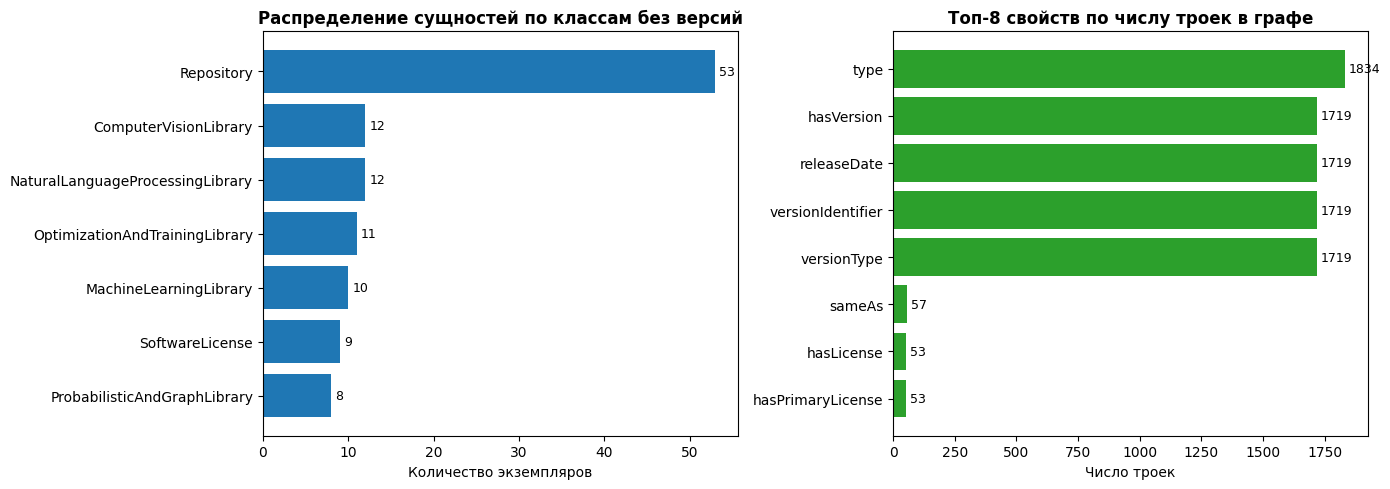

In [33]:
classes_stat = {}
for s, p, o in kg.triples((None, RDF.type, None)):
    c_name = str(o).split("#")[-1]
    classes_stat[c_name] = classes_stat.get(c_name, 0) + 1

df_class_stat = pd.DataFrame(list(classes_stat.items()), columns=["Класс", "Количество экземпляров"]).sort_values(["Количество экземпляров", "Класс"], ascending=[False, True]).reset_index(drop=True)

props_stat = {}
for s, p, o in kg:
    p_name = str(p).split("#")[-1] if "#" in str(p) else str(p).split("/")[-1]
    props_stat[p_name] = props_stat.get(p_name, 0) + 1

df_prop_stat = pd.DataFrame(list(props_stat.items()), columns=["Предикат", "Количество троек"]).sort_values(["Количество троек", "Предикат"], ascending=[False, True]).reset_index(drop=True)

summary_stats = [
    {"Метрика": "Общее количество троек", "Значение": len(kg)},
    {"Метрика": "Количество уникальных субъектов", "Значение": len(set(kg.subjects()))},
    {"Метрика": "Количество уникальных предикатов", "Значение": len(set(kg.predicates()))},
    {"Метрика": "Количество уникальных объектов", "Значение": len(set(kg.objects()))}
]
df_summary = pd.DataFrame(summary_stats)

display(df_summary)
display(df_class_stat)
display(df_prop_stat)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

df_classes_plot = df_class_stat[df_class_stat["Класс"] != "SoftwareVersion"]
bars1 = ax1.barh(df_classes_plot["Класс"], df_classes_plot["Количество экземпляров"], color="#1f77b4")
ax1.set_title("Распределение сущностей по классам без версий", fontsize=12, fontweight="bold")
ax1.set_xlabel("Количество экземпляров")
ax1.invert_yaxis()
for bar in bars1:
    ax1.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width())}", va='center', fontsize=9)

df_props_top = df_prop_stat.head(8)
bars2 = ax2.barh(df_props_top["Предикат"], df_props_top["Количество троек"], color="#2ca02c")
ax2.set_title("Топ-8 свойств по числу троек в графе", fontsize=12, fontweight="bold")
ax2.set_xlabel("Число троек")
ax2.invert_yaxis()
for bar in bars2:
    ax2.text(bar.get_width() + 15, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width())}", va='center', fontsize=9)

plt.tight_layout()
plt.show()


## 4.3. Верификация графа знаний целевыми SPARQL-запросами


Проверка использует шесть запросов из задания 2.

1. **В1.** У каких библиотек экосистемы PyTorch в графе зарегистрировано более 20 версий? Укажите названия и число версий.
2. **В2.** Сколько различных библиотек связано в графе с каждой лицензией?
3. **В3.** Какие пять библиотек занимают первые места по числу зарегистрированных в графе версий? При равенстве расположите их по названию.
4. **В4.** Какие библиотеки компьютерного зрения зависят от PyTorch и распространяются по лицензии Apache License 2.0? Укажите ссылки на их репозитории.
5. **В5.** Какие десять различных сочетаний библиотеки, номера версии и даты выпуска идут первыми по дате публикации в 2023 году? При равенстве дат отсортируйте по названию библиотеки и номеру версии как строке.
6. **В6.** Какие записи библиотек классифицированы в графе как библиотеки обработки естественного языка (NLP)? Укажите адреса их репозиториев.

In [34]:
queries_test = [
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT ?name ?count WHERE {
      ?library pte:libraryName ?name ; pte:versionCount ?count .
      FILTER(?count > 20)
    }
    ORDER BY DESC(?count) LCASE(STR(?name)) ?name
    """, ["Название библиотеки", "Число версий"]),
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT ?licenseName (COUNT(DISTINCT ?library) AS ?count) WHERE {
      ?library pte:hasLicense ?license .
      ?license pte:licenseName ?licenseName .
    }
    GROUP BY ?licenseName
    ORDER BY DESC(?count) ?licenseName
    """, ["Лицензия", "Количество библиотек"]),
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT ?name ?count WHERE {
      ?library pte:libraryName ?name ; pte:versionCount ?count .
    }
    ORDER BY DESC(?count) LCASE(STR(?name)) ?name
    LIMIT 5
    """, ["Библиотека", "Число версий"]),
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT DISTINCT ?name ?repoUrl WHERE {
      ?library a pte:ComputerVisionLibrary ;
               pte:libraryName ?name ;
               pte:dependsOnSoftware pte:PyTorch ;
               pte:hasLicense pte:License_Apache_License_2_0 ;
               pte:hasRepository/pte:repositoryURL ?repoUrl .
    }
    ORDER BY ?name ?repoUrl
    """, ["Библиотека компьютерного зрения", "URL репозитория"]),
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
    SELECT DISTINCT ?name ?version ?date WHERE {
      ?library pte:libraryName ?name ; pte:hasVersion ?release .
      ?release pte:versionIdentifier ?version ; pte:releaseDate ?date .
      FILTER(?date >= "2023-01-01T00:00:00Z"^^xsd:dateTime &&
             ?date < "2024-01-01T00:00:00Z"^^xsd:dateTime)
    }
    ORDER BY ?date ?name ?version
    LIMIT 10
    """, ["Библиотека", "Версия", "Дата релиза в 2023 году"]),
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT DISTINCT ?name ?repoUrl WHERE {
      ?library a pte:NaturalLanguageProcessingLibrary ;
               pte:libraryName ?name ;
               pte:hasRepository/pte:repositoryURL ?repoUrl .
    }
    ORDER BY ?name ?repoUrl
    """, ["Библиотека NLP", "URL репозитория"]),
]

for q_str, col_names in queries_test:
    res = kg.query(q_str)
    rows = [[str(val) for val in r] for r in res]
    df_q = pd.DataFrame(rows, columns=col_names)
    display(df_q)


,Название библиотеки,Число версий
0,pytorch-pretrained-bert,242
1,pytorch-transformers,242
2,PyTorch Lightning,208
3,accelerate,67
4,torchmetrics,63
5,open-clip-torch,57
6,Pyserini,57
7,botorch,55
8,rotary-embedding-torch,53
9,timm,51


,Лицензия,Количество библиотек
0,лицензия MIT,23
1,Apache License 2.0,21
2,модифицированная лицензия BSD,6
3,2-пунктная лицензия BSD,2
4,Free To Use But Restricted,1


,Библиотека,Число версий
0,pytorch-pretrained-bert,242
1,pytorch-transformers,242
2,PyTorch Lightning,208
3,accelerate,67
4,torchmetrics,63


,Библиотека компьютерного зрения,URL репозитория
0,effdet,https://github.com/rwightman/efficientdet-pytorch
1,gfpgan,https://github.com/TencentARC/GFPGAN
2,kornia,https://github.com/kornia/kornia
3,timm,https://github.com/huggingface/pytorch-image-models


,Библиотека,Версия,Дата релиза в 2023 году
0,pyro-ppl,1.8.4,2023-01-03T00:00:00+00:00
1,gpytorch,1.9.1,2023-01-04T00:00:00+00:00
2,open-clip-torch,2.9.2,2023-01-05T00:00:00+00:00
3,botorch,0.8.1,2023-01-06T00:00:00+00:00
4,open-clip-torch,2.9.3,2023-01-09T00:00:00+00:00
5,PyTorch Lightning,1.9.0,2023-01-17T00:00:00+00:00
6,nerfacc,0.3.3,2023-01-18T00:00:00+00:00
7,open-clip-torch,2.10.0,2023-01-23T00:00:00+00:00
8,open-clip-torch,2.10.1,2023-01-24T00:00:00+00:00
9,pytorch-pretrained-bert,4.26.0,2023-01-25T00:00:00+00:00


,Библиотека NLP,URL репозитория
0,STonKGs,https://github.com/stonkgs/stonkgs
1,Stanza,https://github.com/stanfordnlp/stanza
2,allennlp,https://github.com/allenai/allennlp
3,attacut,https://github.com/PyThaiNLP/attacut
4,bert-score,https://github.com/Tiiiger/bert_score
5,flair,https://github.com/flairNLP/flair
6,fschat,https://github.com/lm-sys/fastchat
7,peft,https://github.com/huggingface/peft
8,pytorch-pretrained-bert,https://github.com/huggingface/transformers
9,pytorch-transformers,https://github.com/huggingface/transformers


## 4.4. Итоги выполнения заданий 3 и 4


1. Задание 3:
   - Разработана OWL-онтология предметной области в пространстве имен `http://example.org/pytorch-ecosystem#`
   - Реализована таксономия из 10 классов, включая предметные категории компьютерного зрения, обработки естественного языка, вероятностных и графовых моделей, оптимизации и распределенного обучения
   - Свойства разделены на объектные и литеральные, у каждого свойства специфицированы `rdfs:domain` и `rdfs:range`
   - Объявлены функциональные свойства `owl:FunctionalProperty`: `hasPrimaryLicense`, `hasSourceCodeRepository`, `versionIdentifier`, `repositoryURL`, `licenseName`, `versionCount`
   - Все сущности снабжены двуязычными аннотациями `rdfs:label` и подробными комментариями `rdfs:comment` на русском и английском языках
   - Зафиксированы соответствия `owl:equivalentClass` и `owl:equivalentProperty` к сущностям Wikidata
   - Построена матрица покрытия 12 вопросов доменными элементами онтологии
   - Текст онтологии приведен в файле `ontology.ttl`

2. Задание 4:
   - Граф собран из сохранённых метаданных 52 библиотек экосистемы и включает центральный узел PyTorch
   - Для 53 библиотек и четырёх лицензий проверены связи `owl:sameAs` с Wikidata
   - Собранный граф включает 9 302 троек и 1 834 уникальных субъектов
   - Рассчитана и визуализирована подробная статистика по классам и предикатам
   - Работоспособность графа подтверждена серией целевых SPARQL-запросов
   - Граф, собранный во временном каталоге, совпадает с `knowledge_graph.ttl` в репозитории

# Глава 5. Сбор текстовой информации по сущностям (Задание 5)

<p class="task" id="5"></p>



### 5.1. Источники и структура корпуса

Список сущностей берётся из `data/task1_entities.json`: это 52 библиотеки, выбранные в задании 1.
Вспомогательные узлы графа — лицензии, репозитории, релизы и центральный узел PyTorch — не являются дополнительными сущностями этой выборки.

Для каждой библиотеки используется README из её репозитория GitHub. Скрипт
`scripts/01_fetch_data_and_corpus.py` ранее сохранил первые 4 000 символов README в `data/corpus.jsonl`.
В этой работе корпус собирается из этих локальных выдержек: повторное скачивание могло бы изменить тексты и цитаты из задания 2.
Это **повторная сборка сохранённого снимка**, а не новая загрузка страниц.
Исходный скрипт допускает шаблонный текст при ошибке скачивания; ниже отдельно проверяется, что таких подстановок в используемом корпусе нет.

Формат результата — UTF-8 JSONL: один JSON-объект на строку, переводы строк внутри текста экранированы.
Разметка Markdown/RST сохранена, чтобы не менять исходные цитаты. Результат записывается в
[`data/tasks_5_6/corpus.jsonl`](../data/tasks_5_6/corpus.jsonl).

| Поле | Содержание |
| :--- | :--- |
| `id`, `name` | QID Wikidata и название библиотеки |
| `source_url` | Адрес исходного файла README; один источник на запись |
| `source_type` | `github_readme` |
| `description` | Описание из сохранённой выгрузки Wikidata |
| `text` | Сохранённая выдержка README, не более 4 000 символов |
| `text_sha256` | Контрольная сумма текста для проверки воспроизводимости |
| `provenance` | Путь к локальному снимку, из которого взят текст |

Дата первоначального скачивания и commit SHA в исходном корпусе не записаны. Поэтому ссылки указывают
на изменяемые ветки репозиториев; воспроизводимость обеспечивается локальным текстом и его контрольной суммой.


In [35]:
import hashlib
import json
import platform
from collections import Counter
from importlib.metadata import version
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import pyshacl
import owlrl
from IPython.display import display
from rdflib import Graph, Namespace, RDF, RDFS, OWL, XSD, Literal, URIRef
from rdflib.compare import isomorphic

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)

project = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'knowledge_graph.ttl').is_file() and (p / 'data/corpus.jsonl').is_file()
)
artifacts = project / 'data' / 'tasks_5_6'
artifacts.mkdir(parents=True, exist_ok=True)
PTE = Namespace('http://example.org/pytorch-ecosystem#')
WD = Namespace('http://www.wikidata.org/entity/')
WDT = Namespace('http://www.wikidata.org/prop/direct/')
SH = Namespace('http://www.w3.org/ns/shacl#')

environment = {'Python': platform.python_version()}
environment.update({name: version(name) for name in ['rdflib', 'pyshacl', 'owlrl', 'pandas']})
display(pd.DataFrame(environment.items(), columns=['Компонент', 'Версия']))
(artifacts / 'environment.json').write_text(
    json.dumps(environment, ensure_ascii=False, indent=2), encoding='utf-8'
)


,Компонент,Версия
0,Python,3.11.9
1,rdflib,7.6.0
2,pyshacl,0.40.1
3,owlrl,7.6.2
4,pandas,2.2.3


109

In [36]:
entities = json.loads((project / 'data/task1_entities.json').read_text(encoding='utf-8'))
original_corpus = [
    json.loads(line)
    for line in (project / 'data/corpus.jsonl').read_text(encoding='utf-8').splitlines()
    if line.strip()
]
entity_ids = {entity['qid'] for entity in entities}
source_ids = [doc['id'] for doc in original_corpus]
assert len(entity_ids) == len(entities) == 52
assert len(source_ids) == len(set(source_ids)), 'В исходном корпусе есть повторяющиеся QID'
assert set(source_ids) == entity_ids, 'Состав корпуса отличается от выборки задания 1'

corpus = []
for doc in sorted(original_corpus, key=lambda d: (d['name'].casefold(), d['id'])):
    source = urlparse(doc['source_url'])
    assert source.scheme == 'https' and source.netloc == 'raw.githubusercontent.com'
    assert source.path.lower().endswith(('readme.md', 'readme.rst'))
    assert isinstance(doc['text'], str) and doc['text'].strip()
    assert len(doc['text']) <= 4000
    assert 'is an open-source Python library designed for machine learning workflows' not in doc['text']
    corpus.append({
        **doc,
        'source_type': 'github_readme',
        'text_sha256': hashlib.sha256(doc['text'].encode('utf-8')).hexdigest(),
        'provenance': 'data/corpus.jsonl',
    })

corpus_path = artifacts / 'corpus.jsonl'
with corpus_path.open('w', encoding='utf-8', newline='\n') as file:
    for doc in corpus:
        file.write(json.dumps(doc, ensure_ascii=False) + '\n')

# Обратное чтение проверяет именно сохранённый JSONL, а не только список в памяти.
loaded_corpus = [json.loads(line) for line in corpus_path.read_text(encoding='utf-8').splitlines()]
assert loaded_corpus == corpus
assert {doc['id'] for doc in loaded_corpus} == entity_ids
for doc in loaded_corpus:
    assert hashlib.sha256(doc['text'].encode('utf-8')).hexdigest() == doc['text_sha256']

lengths = [len(doc['text']) for doc in loaded_corpus]
corpus_stats = {
    'Сущностей в выборке': len(entity_ids),
    'Документов / строк JSONL': len(loaded_corpus),
    'Сущностей с текстом и источником': len({doc['id'] for doc in loaded_corpus}),
    'Охват выборки, %': round(len(loaded_corpus) / len(entity_ids) * 100, 2),
    'Уникальных URL источников': len({doc['source_url'] for doc in loaded_corpus}),
    'Минимальная длина текста': min(lengths),
    'Максимальная длина текста': max(lengths),
    'Средняя длина текста': round(sum(lengths) / len(lengths), 2),
    'Размер JSONL, байт': corpus_path.stat().st_size,
}
display(pd.DataFrame(corpus_stats.items(), columns=['Метрика', 'Значение']))
print('Сохранено:', corpus_path.relative_to(project).as_posix())
print('Обратное чтение JSONL, покрытие QID и контрольные суммы: OK')


,Метрика,Значение
0,Сущностей в выборке,52.00
1,Документов / строк JSONL,52.00
2,Сущностей с текстом и источником,52.00
3,"Охват выборки, %",100.00
4,Уникальных URL источников,51.00
5,Минимальная длина текста,2069.00
6,Максимальная длина текста,4000.00
7,Средняя длина текста,3885.92
8,"Размер JSONL, байт",224584.00


Сохранено: data/tasks_5_6/corpus.jsonl
Обратное чтение JSONL, покрытие QID и контрольные суммы: OK


### 5.2. Источник для каждой сущности

Таблица содержит все 52 сущности, а не только примеры. Один README может соответствовать нескольким
QID: `pytorch-pretrained-bert` и `pytorch-transformers` используют общий репозиторий Transformers.
Требование проверяется по QID: у каждой сущности есть непустой текст и ссылка на источник.


In [37]:
sources_df = pd.DataFrame([{
    'QID': doc['id'],
    'Библиотека': doc['name'],
    'Источник': doc['source_url'],
    'Символов': len(doc['text']),
} for doc in loaded_corpus])
display(sources_df)
sources_df.to_csv(artifacts / 'corpus_sources.csv', index=False, encoding='utf-8-sig')

print('Пример записи JSONL (текст сокращён только при выводе):')
example = next(doc for doc in loaded_corpus if doc['name'] == 'torchvision')
print(json.dumps({**example, 'text': example['text'][:800] + '…'}, ensure_ascii=False, indent=2))


,QID,Библиотека,Источник,Символов
0,Q116908792,accelerate,https://raw.githubusercontent.com/huggingface/accelerate/master/README.md,4000
1,Q107382302,allennlp,https://raw.githubusercontent.com/allenai/allennlp/master/README.md,4000
2,Q107382376,attacut,https://raw.githubusercontent.com/PyThaiNLP/attacut/master/README.md,3419
3,Q107382224,bert-score,https://raw.githubusercontent.com/Tiiiger/bert_score/master/README.md,4000
4,Q107382330,botorch,https://raw.githubusercontent.com/meta-pytorch/botorch/master/README.md,4000
5,Q107382311,captum,https://raw.githubusercontent.com/meta-pytorch/captum/master/README.md,4000
6,Q107382139,catalyst,https://raw.githubusercontent.com/catalyst-team/catalyst/master/README.md,4000
7,Q120549792,clean-fid,https://raw.githubusercontent.com/GaParmar/clean-fid/master/README.md,4000
8,Q120596958,effdet,https://raw.githubusercontent.com/rwightman/efficientdet-pytorch/master/README.md,4000
9,Q120550306,face-alignment,https://raw.githubusercontent.com/1adrianb/face-alignment/master/README.md,4000


Пример записи JSONL (текст сокращён только при выводе):
{
  "id": "Q107381670",
  "name": "torchvision",
  "source_url": "https://raw.githubusercontent.com/pytorch/vision/master/README.md",
  "description": "Python library",
  "text": "# torchvision\n\n[![total torchvision downloads](https://pepy.tech/badge/torchvision)](https://pepy.tech/project/torchvision)\n[![documentation](https://img.shields.io/badge/dynamic/json.svg?label=docs&url=https%3A%2F%2Fpypi.org%2Fpypi%2Ftorchvision%2Fjson&query=%24.info.version&colorB=brightgreen&prefix=v)](https://pytorch.org/vision/stable/index.html)\n\nThe torchvision package consists of popular datasets, model architectures, and common image transformations for computer\nvision.\n\n## Installation\n\nPlease refer to the [official\ninstructions](https://pytorch.org/get-started/locally/) to install the stable\nversions of `torch` and `torchvision` on your system.\n\nTo build source, refer to our [contributing\npage](https://github.com/pytorch/vision/b

# Глава 6. Проверка данных (SHACL) и логический вывод (OWL 2 RL) (Задание 6)

<p class="task" id="6"></p>



### 6.1. Ограничения SHACL

Проверяются **пять разных видов ограничений**, что превышает требование «не менее трёх».
Формы берутся из `shapes.shacl.ttl`. В рабочую копию добавлена явная цель `pte:AudioProcessingLibrary`,
чтобы в перечне целей были представлены все категории библиотек из задания 3.
Сами ограничения не ослабляются. Рабочая копия сохраняется в `data/tasks_5_6/shapes.shacl.ttl`.

| Вид | Ограничение | Что проверяется |
| :--- | :--- | :--- |
| Кардинальность | `sh:minCount`, `sh:maxCount` | Ровно одно имя и основной репозиторий; хотя бы одна лицензия; ровно один URL репозитория; хотя бы один идентификатор версии |
| Тип данных | `sh:datatype` | Имя и идентификатор версии — `xsd:string`; число версий — `xsd:integer`; URL — `xsd:anyURI`; дата — `xsd:dateTime` |
| Класс значения | `sh:class` | Значение `hasLicense` принадлежит `pte:SoftwareLicense` |
| Диапазон | `sh:minInclusive 0` | Число версий неотрицательно |
| Шаблон | `sh:pattern` | URL соответствует `https://github.com/owner/repo` с допустимым завершающим `/` |

Для даты и числа версий проверяются имеющиеся значения: обязательность их наличия формами не задана.
Шаблон URL проверяет структуру строки, но не доступность репозитория в сети.

Проверка выполняется **до OWL-вывода**, с `inference='none'`. Онтология передаётся отдельно в `ont_graph`,
чтобы SHACL учитывал иерархию классов. Предварительное применение `rdfs:range` могло бы автоматически
приписать ошибочному объекту класс лицензии и скрыть нарушение `sh:class`.


In [38]:
kg = Graph().parse(project / 'knowledge_graph.ttl', format='turtle')
ontology = Graph().parse(project / 'ontology.ttl', format='turtle')
shapes = Graph().parse(project / 'shapes.shacl.ttl', format='turtle')
shapes.add((PTE.LibraryShape, SH.targetClass, PTE.AudioProcessingLibrary))
shapes.serialize(destination=artifacts / 'shapes.shacl.ttl', format='turtle')
assert isomorphic(shapes, Graph().parse(artifacts / 'shapes.shacl.ttl', format='turtle'))

def clone_graph(graph):
    result = Graph()
    for prefix, namespace in graph.namespaces():
        result.bind(prefix, namespace)
    for triple in graph:
        result.add(triple)
    return result

def short(term):
    return term.n3(kg.namespace_manager) if term is not None else '—'

def validate_and_save(graph, name):
    conforms, report_graph, report_text = pyshacl.validate(
        data_graph=graph,
        shacl_graph=shapes,
        ont_graph=ontology,
        inference='none',
        abort_on_first=False,
        meta_shacl=True,
        advanced=False,
        inplace=False,
    )
    (artifacts / f'{name}.txt').write_text(report_text, encoding='utf-8')
    report_graph.serialize(destination=artifacts / f'{name}.ttl', format='turtle')
    return conforms, report_graph, report_text

def report_rows(report):
    rows = []
    for result in report.subjects(RDF.type, SH.ValidationResult):
        rows.append({
            'Узел': short(report.value(result, SH.focusNode)),
            'Свойство': short(report.value(result, SH.resultPath)),
            'Компонент': str(report.value(result, SH.sourceConstraintComponent)).split('#')[-1],
            'Значение': short(report.value(result, SH.value)),
            'Сообщение': str(report.value(result, SH.resultMessage)),
        })
    return sorted(rows, key=lambda row: (row['Компонент'], row['Узел'], row['Свойство']))

# Проверяем, что все библиотеки, включая аудио и центральный PyTorch, входят в область проверки.
library_targets = set(shapes.objects(PTE.LibraryShape, SH.targetClass))
targeted_libraries = {s for cls in library_targets for s in kg.subjects(RDF.type, cls)}
all_libraries = set(kg.subjects(PTE.libraryName, None))
assert targeted_libraries == all_libraries
graph_qids = {
    str(wd).rsplit('/', 1)[-1]
    for library in all_libraries for wd in kg.objects(library, OWL.sameAs)
}
assert entity_ids <= graph_qids, 'Не все сущности корпуса представлены в графе'
print('Троек данных:', len(kg))
print('Троек онтологии:', len(ontology))
print('Библиотек, охваченных формой:', len(targeted_libraries))
print('Репозиториев:', len(set(kg.subjects(RDF.type, PTE.Repository))))
print('Версий:', len(set(kg.subjects(RDF.type, PTE.SoftwareVersion))))


Троек данных: 9302
Троек онтологии: 155
Библиотек, охваченных формой: 53
Репозиториев: 53
Версий: 1719


## 6.2. Результат pyshacl на исходных данных


Ниже выводится полный текст отчёта pyshacl. Его текстовая и RDF-версии сохраняются рядом с ноутбуком
в каталоге результатов. Отсутствие нарушений означает соответствие **заданным формам**,
а не доказательство фактической корректности всех сведений из Wikidata.

In [39]:
kg_before_validation = set(kg)
base_conforms, base_report, base_text = validate_and_save(kg, 'shacl_original')
print(base_text)
print('Число нарушений:', len(report_rows(base_report)))
assert base_conforms and not report_rows(base_report)
assert set(kg) == kg_before_validation, 'Проверка изменила исходный граф'


Validation Report
Conforms: True

Число нарушений: 0


## 6.3. Контрольный эксперимент: выявление пяти типов нарушений


В исходном снимке нарушений выбранных ограничений не обнаружено: данные и ограничения оставлены без исправлений.
Чтобы показать работу диагностики и процедуру исправления, создаётся **отдельная копия графа с искусственными ошибками**.
Эти ошибки не выдаются за обнаруженные дефекты исходного набора. В копию вносятся:

1. Второе название библиотеки — нарушение максимальной кардинальности.
2. Число вместо строкового идентификатора версии — нарушение типа данных.
3. Ссылка `hasLicense` на репозиторий — нарушение класса значения.
4. Отрицательное число версий — нарушение диапазона.
5. URL с `http` вместо `https` — нарушение шаблона при сохранённом типе `xsd:anyURI`.

Изменения подобраны так, чтобы каждая ошибка нарушала один соответствующий вид ограничения.
Выполняется тот же набор форм и тот же режим проверки.

In [40]:
demo = clone_graph(kg)
library = PTE.Lib_PyKEEN_Q96631404
repository = kg.value(library, PTE.hasSourceCodeRepository)
release = sorted(kg.objects(library, PTE.hasVersion), key=str)[0]
assert repository is not None

patches = [
    (library, PTE.libraryName, Literal('Второе тестовое имя', datatype=XSD.string), False),
    (release, PTE.versionIdentifier, Literal(123, datatype=XSD.integer), True),
    (library, PTE.hasLicense, repository, True),
    (library, PTE.versionCount, Literal(-1, datatype=XSD.integer), True),
    (repository, PTE.repositoryURL, Literal('http://github.com/pykeen/pykeen', datatype=XSD.anyURI), True),
]
original_values = {}
for subject, predicate, bad_value, replace in patches:
    original_values[(subject, predicate)] = list(kg.objects(subject, predicate))
    if replace:
        demo.remove((subject, predicate, None))
    demo.add((subject, predicate, bad_value))

demo.serialize(destination=artifacts / 'validation_demo_invalid.ttl', format='turtle')
demo_conforms, demo_report, demo_text = validate_and_save(demo, 'shacl_demo_before')
print(demo_text)
violations = report_rows(demo_report)
display(pd.DataFrame(violations))
expected_components = {
    'MaxCountConstraintComponent', 'DatatypeConstraintComponent',
    'ClassConstraintComponent', 'MinInclusiveConstraintComponent', 'PatternConstraintComponent',
}
assert not demo_conforms
assert len(violations) == 5
assert {row['Компонент'] for row in violations} == expected_components


Validation Report
Conforms: False
Results (5):
Constraint Violation in ClassConstraintComponent (http://www.w3.org/ns/shacl#ClassConstraintComponent):
	Severity: sh:Violation
	Source Shape: [ sh:class pte:SoftwareLicense ; sh:message Literal("Лицензия библиотеки должна быть объектом класса SoftwareLicense.", lang=ru) ; sh:minCount Literal("1", datatype=xsd:integer) ; sh:path pte:hasLicense ]
	Focus Node: pte:Lib_PyKEEN_Q96631404
	Value Node: pte:Repo_PyKEEN_Q96631404
	Result Path: pte:hasLicense
	Message: Лицензия библиотеки должна быть объектом класса SoftwareLicense.
Constraint Violation in DatatypeConstraintComponent (http://www.w3.org/ns/shacl#DatatypeConstraintComponent):
	Severity: sh:Violation
	Source Shape: [ sh:datatype xsd:string ; sh:message Literal("Идентификатор версии должен быть строкой.", lang=ru) ; sh:minCount Literal("1", datatype=xsd:integer) ; sh:path pte:versionIdentifier ]
	Focus Node: pte:Ver_PyKEEN_Q96631404_0_0_26_18
	Value Node: Literal("123", datatype=xsd:int

,Узел,Свойство,Компонент,Значение,Сообщение
0,pte:Lib_PyKEEN_Q96631404,pte:hasLicense,ClassConstraintComponent,pte:Repo_PyKEEN_Q96631404,Лицензия библиотеки должна быть объектом класса SoftwareLicense.
1,pte:Ver_PyKEEN_Q96631404_0_0_26_18,pte:versionIdentifier,DatatypeConstraintComponent,"""123""^^xsd:integer",Идентификатор версии должен быть строкой.
2,pte:Lib_PyKEEN_Q96631404,pte:libraryName,MaxCountConstraintComponent,—,Библиотека должна иметь ровно одно строковое название (libraryName).
3,pte:Lib_PyKEEN_Q96631404,pte:versionCount,MinInclusiveConstraintComponent,"""-1""^^xsd:integer",Число версий должно быть неотрицательным целым числом.
4,pte:Repo_PyKEEN_Q96631404,pte:repositoryURL,PatternConstraintComponent,"""http://github.com/pykeen/pykeen""^^xsd:anyURI",URL репозитория должен указывать на валидный адрес GitHub репозитория.


## 6.4. Решения по каждому типу нарушения и повторная проверка


| Вид нарушения в эксперименте | Решение | Что сделано и почему |
| :--- | :--- | :--- |
| Кардинальность | Данные исправлены | Удалено добавленное тестовое имя, восстановлено единственное исходное название. В модели задано одно основное имя. |
| Тип данных | Данные исправлены | Восстановлен исходный строковый идентификатор версии. Преобразование числа `123` в строку не восстановило бы правильный номер релиза. |
| Класс значения | Данные исправлены | Восстановлена исходная ссылка на узел лицензии. Репозиторий не объявляется лицензией только ради прохождения проверки. |
| Диапазон | Данные исправлены | Восстановлено исходное неотрицательное число версий. Отрицательное число не имеет смысла для счётчика. |
| Шаблон | Данные исправлены | Восстановлен исходный HTTPS-адрес репозитория с типом `xsd:anyURI`. Формат URL согласован с сохранёнными данными. |

Ограничения не ослаблены; нарушений в исправленной копии не оставлено. Восстановление выполняется
по значениям исходного графа, сохранённым **до** эксперимента. Для реальных данных выбор нового значения
потребовал бы сверки с источником. Сравнение множеств троек проверяет, что исправленная копия полностью совпала с исходной.

In [41]:
repaired = clone_graph(demo)
for (subject, predicate), values in original_values.items():
    repaired.remove((subject, predicate, None))
    for value in values:
        repaired.add((subject, predicate, value))
assert set(repaired) == set(kg)

fixed_conforms, fixed_report, fixed_text = validate_and_save(repaired, 'shacl_demo_after')
print(fixed_text)
assert fixed_conforms and not report_rows(fixed_report)
validation_summary = pd.DataFrame([
    {'Набор': 'Исходный граф', 'Conforms': base_conforms, 'Нарушений': len(report_rows(base_report))},
    {'Набор': 'Копия с пятью искусственными ошибками', 'Conforms': demo_conforms, 'Нарушений': len(violations)},
    {'Набор': 'Исправленная копия', 'Conforms': fixed_conforms, 'Нарушений': len(report_rows(fixed_report))},
])
display(validation_summary)
validation_summary.to_csv(artifacts / 'validation_summary.csv', index=False, encoding='utf-8-sig')


Validation Report
Conforms: True



,Набор,Conforms,Нарушений
0,Исходный граф,True,0
1,Копия с пятью искусственными ошибками,False,5
2,Исправленная копия,True,0


## 6.5. Дедуктивный логический вывод OWL 2 RL


Для вывода берётся объединение **исходного графа данных и онтологии**, без SHACL-форм и экспериментальных ошибок.
`owlrl.DeductiveClosure(owlrl.OWLRL_Semantics)` достраивает замыкание по правилам OWL 2 RL.
Перед запуском фиксируется множество утверждённых троек; новые тройки вычисляются как точная разность
`после − до`. Поэтому уже существовавшие связи не попадают в список добавленных.

Полная разность сохраняется в [`owlrl_added_triples.ttl`](../data/tasks_5_6/owlrl_added_triples.ttl).
Она содержит как предметные выводы, так и служебные утверждения о классах, свойствах, типах данных и рефлексивные `owl:sameAs`.
Общее число добавленных троек нельзя интерпретировать как число новых независимых фактов о библиотеках.

In [42]:
inferred = clone_graph(kg)
for triple in ontology:
    inferred.add(triple)
asserted = set(inferred)

owlrl.DeductiveClosure(
    owlrl.OWLRL_Semantics, axiomatic_triples=False, datatype_axioms=False
).expand(inferred)

added = set(inferred) - asserted
assert asserted <= set(inferred), 'Вывод должен только добавлять тройки'
assert len(inferred) == len(asserted) + len(added)
assert added and not (added & asserted)

delta_graph = Graph()
for prefix, namespace in inferred.namespaces():
    delta_graph.bind(prefix, namespace)
for triple in added:
    delta_graph.add(triple)
delta_path = artifacts / 'owlrl_added_triples.ttl'
delta_graph.serialize(destination=delta_path, format='turtle')
assert isomorphic(delta_graph, Graph().parse(delta_path, format='turtle'))

reasoning_stats = {
    'Троек данных': len(kg),
    'Троек онтологии': len(ontology),
    'До вывода (объединение)': len(asserted),
    'После вывода': len(inferred),
    'Добавлено троек': len(added),
    'Из них рефлексивных owl:sameAs': sum(p == OWL.sameAs and s == o for s, p, o in added),
}
display(pd.DataFrame(reasoning_stats.items(), columns=['Метрика', 'Значение']))
print('Все добавленные тройки сохранены:', delta_path.relative_to(project).as_posix())
(artifacts / 'owlrl_summary.json').write_text(
    json.dumps(reasoning_stats, ensure_ascii=False, indent=2), encoding='utf-8'
)

predicate_counts = Counter(p for s, p, o in added)
display(pd.DataFrame([
    {'Предикат добавленной тройки': short(p), 'Количество': count}
    for p, count in sorted(predicate_counts.items(), key=lambda item: (-item[1], str(item[0])))
]))


,Метрика,Значение
0,Троек данных,9302
1,Троек онтологии,155
2,До вывода (объединение),9457
3,После вывода,22381
4,Добавлено троек,12924
5,Из них рефлексивных owl:sameAs,3935


Все добавленные тройки сохранены: data/tasks_5_6/owlrl_added_triples.ttl


,Предикат добавленной тройки,Количество
0,rdf:type,6025
1,owl:sameAs,3992
2,pte:hasVersion,1719
3,<http://www.wikidata.org/prop/direct/P1547>,208
4,pte:dependsOnSoftware,156
5,<http://www.wikidata.org/prop/direct/P1324>,106
6,<http://www.wikidata.org/prop/direct/P275>,106
7,rdfs:subClassOf,71
8,pte:hasLicense,53
9,pte:hasPrimaryLicense,53


## 6.6. Анализ добавленных троек и механизмов вывода


Ниже показаны примеры четырёх механизмов вывода с исходными предпосылками:

* **Иерархия классов:** экземпляр `ProbabilisticAndGraphLibrary` становится экземпляром `MachineLearningLibrary`, а затем `SoftwareLibrary`.
* **Эквивалентность классов:** принадлежность локальному `SoftwareLibrary` переносится на эквивалентный класс `wd:Q188860`.
* **Эквивалентность свойств:** связь `dependsOnSoftware` порождает связь `wdt:P1547`.
* **Тождество сущностей:** свойства локальной библиотеки переносятся на её QID через `owl:sameAs`.

Для каждого примера программно проверяется, что тройка отсутствовала до вывода и присутствует в сохранённой разности.
Эквивалентности взяты из онтологии задания 3; корректность их предметного смысла сам механизм вывода не проверяет.
Вывод выполняется локально и не загружает дополнительные сведения из Wikidata.

In [43]:
name = kg.value(library, PTE.libraryName)
wd_library = kg.value(library, OWL.sameAs)
examples = [
    ('Иерархия классов', (library, RDF.type, PTE.MachineLearningLibrary), [
        (library, RDF.type, PTE.ProbabilisticAndGraphLibrary),
        (PTE.ProbabilisticAndGraphLibrary, RDFS.subClassOf, PTE.MachineLearningLibrary),
    ]),
    ('Транзитивная иерархия', (library, RDF.type, PTE.SoftwareLibrary), [
        (library, RDF.type, PTE.MachineLearningLibrary),
        (PTE.MachineLearningLibrary, RDFS.subClassOf, PTE.SoftwareLibrary),
    ]),
    ('Эквивалентность классов', (library, RDF.type, WD.Q188860), [
        (library, RDF.type, PTE.SoftwareLibrary),
        (PTE.SoftwareLibrary, OWL.equivalentClass, WD.Q188860),
    ]),
    ('Эквивалентность свойств', (library, WDT.P1547, PTE.PyTorch), [
        (library, PTE.dependsOnSoftware, PTE.PyTorch),
        (PTE.dependsOnSoftware, OWL.equivalentProperty, WDT.P1547),
    ]),
    ('Тождество owl:sameAs', (wd_library, PTE.libraryName, name), [
        (library, OWL.sameAs, wd_library),
        (library, PTE.libraryName, name),
    ]),
]

def triple_text(triple):
    return ' '.join(short(term) for term in triple) + ' .'

example_rows = []
for mechanism, triple, premises in examples:
    assert triple not in asserted and triple in added
    assert all(premise in inferred for premise in premises)
    example_rows.append({
        'Механизм': mechanism,
        'Добавленная тройка': triple_text(triple),
        'Предпосылки': '\n'.join(
            ('[исходная] ' if premise in asserted else '[выведенная] ') + triple_text(premise)
            for premise in premises
        ),
    })
display(pd.DataFrame(example_rows))
(artifacts / 'owlrl_examples.json').write_text(
    json.dumps(example_rows, ensure_ascii=False, indent=2), encoding='utf-8'
)

print('Первые 15 новых троек о локальных библиотеках (детерминированная сортировка):')
library_triples = sorted(
    (triple for triple in added if triple[0] in all_libraries and triple[1] != OWL.sameAs),
    key=lambda triple: tuple(term.n3() for term in triple),
)
for triple in library_triples[:15]:
    print(triple_text(triple))


,Механизм,Добавленная тройка,Предпосылки
0,Иерархия классов,pte:Lib_PyKEEN_Q96631404 rdf:type pte:MachineLearningLibrary .,[исходная] pte:Lib_PyKEEN_Q96631404 rdf:type pte:ProbabilisticAndGraphLibrary .\n[исходная] pte:ProbabilisticAndGraphLibrary rdfs:subClassOf pte:MachineLearningLibrary .
1,Транзитивная иерархия,pte:Lib_PyKEEN_Q96631404 rdf:type pte:SoftwareLibrary .,[выведенная] pte:Lib_PyKEEN_Q96631404 rdf:type pte:MachineLearningLibrary .\n[исходная] pte:MachineLearningLibrary rdfs:subClassOf pte:SoftwareLibrary .
2,Эквивалентность классов,pte:Lib_PyKEEN_Q96631404 rdf:type wd:Q188860 .,[выведенная] pte:Lib_PyKEEN_Q96631404 rdf:type pte:SoftwareLibrary .\n[исходная] pte:SoftwareLibrary owl:equivalentClass wd:Q188860 .
3,Эквивалентность свойств,pte:Lib_PyKEEN_Q96631404 <http://www.wikidata.org/prop/direct/P1547> pte:PyTorch .,[исходная] pte:Lib_PyKEEN_Q96631404 pte:dependsOnSoftware pte:PyTorch .\n[исходная] pte:dependsOnSoftware owl:equivalentProperty <http://www.wikidata.org/prop/direct/P1547> .
4,Тождество owl:sameAs,"wd:Q96631404 pte:libraryName ""PyKEEN""^^xsd:string .","[исходная] pte:Lib_PyKEEN_Q96631404 owl:sameAs wd:Q96631404 .\n[исходная] pte:Lib_PyKEEN_Q96631404 pte:libraryName ""PyKEEN""^^xsd:string ."


Первые 15 новых троек о локальных библиотеках (детерминированная сортировка):
pte:Lib_PyKEEN_Q96631404 pte:dependsOnSoftware wd:Q47509047 .
pte:Lib_PyKEEN_Q96631404 rdf:type pte:MachineLearningLibrary .
pte:Lib_PyKEEN_Q96631404 rdf:type pte:SoftwareLibrary .
pte:Lib_PyKEEN_Q96631404 rdf:type owl:Thing .
pte:Lib_PyKEEN_Q96631404 rdf:type wd:Q188860 .
pte:Lib_PyKEEN_Q96631404 rdf:type wd:Q21169670 .
pte:Lib_PyKEEN_Q96631404 <http://www.wikidata.org/prop/direct/P1324> pte:Repo_PyKEEN_Q96631404 .
pte:Lib_PyKEEN_Q96631404 <http://www.wikidata.org/prop/direct/P1547> pte:PyTorch .
pte:Lib_PyKEEN_Q96631404 <http://www.wikidata.org/prop/direct/P1547> wd:Q47509047 .
pte:Lib_PyKEEN_Q96631404 <http://www.wikidata.org/prop/direct/P275> pte:License_лицензия_MIT .
pte:Lib_PyTorch_Lightning_Q85847011 pte:dependsOnSoftware wd:Q47509047 .
pte:Lib_PyTorch_Lightning_Q85847011 rdf:type pte:MachineLearningLibrary .
pte:Lib_PyTorch_Lightning_Q85847011 rdf:type pte:SoftwareLibrary .
pte:Lib_PyTorch_Lightning_

## 6.7. Итоги выполнения заданий 5 и 6


1. **Задание 5:** собран JSONL из сохранённых README для всех 52 сущностей выборки; для каждой приведена ссылка на источник. Проверены уникальность QID, непустота текстов, покрытие выборки и обратное чтение файла.
2. **Задание 6, проверка:** применены пять видов ограничений SHACL. На исходном графе получен полный отчёт pyshacl. В отдельной экспериментальной копии выявлены пять заранее внесённых ошибок; по каждому типу объяснено исправление, после которого проверка повторена.
3. **Задание 6, вывод:** выполнен OWL 2 RL, сохранено полное множество добавленных троек; приведены примеры с предпосылками и проверкой отсутствия этих троек в исходном графе.

Основные файлы результатов:

| Файл в `data/tasks_5_6/` | Содержание |
| :--- | :--- |
| `corpus.jsonl`, `corpus_sources.csv` | Корпус и полный список источников |
| `shapes.shacl.ttl` | Формы, использованные в проверке |
| `shacl_original.txt`, `shacl_original.ttl` | Полный результат pyshacl для исходных данных |
| `validation_demo_invalid.ttl` | Экспериментальная копия с искусственными ошибками |
| `shacl_demo_before.*`, `shacl_demo_after.*` | Полные результаты pyshacl до и после исправления копии |
| `validation_summary.csv` | Сводка трёх проверок |
| `owlrl_added_triples.ttl` | Все добавленные тройки |
| `owlrl_summary.json`, `owlrl_examples.json` | Статистика вывода и примеры с объяснениями |
| `environment.json` | Версии Python и библиотек |

Исходные граф, онтология и корпус предыдущих заданий не изменяются.

In [44]:
assert len(loaded_corpus) == len(entity_ids) == 52
assert base_conforms and not demo_conforms and fixed_conforms
assert len(expected_components) == 5
assert set(kg) == kg_before_validation
assert set(repaired) == set(kg)
assert set(inferred) == asserted | added

print(f'Задание 5: {len(loaded_corpus)}/{len(entity_ids)} сущностей с текстом и источником; JSONL сохранён.')
print('Задание 6: исходный граф — Conforms: True; эксперимент — 5 нарушений; после исправления — 0.')
print(f'OWL 2 RL: {len(asserted):,} → {len(inferred):,} троек; добавлено {len(added):,}.')
print('Все итоговые проверки пройдены.')


Задание 5: 52/52 сущностей с текстом и источником; JSONL сохранён.
Задание 6: исходный граф — Conforms: True; эксперимент — 5 нарушений; после исправления — 0.
OWL 2 RL: 9,457 → 22,381 троек; добавлено 12,924.
Все итоговые проверки пройдены.


# Глава 7. Сводная таблица итоговых показателей проекта

В таблице ниже сведены ключевые количественные и качественные характеристики созданной базы знаний экосистемы PyTorch по всем разделам контрольной работы.

| Раздел / Компонент | Метрика / Критерий | Значение | Статус проверки |
| :--- | :--- | :--- | :--- |
| **Домен (Задание 1)** | Число библиотек выборки | **52** (в диапазоне 30–60) | Выполнено |
| | Основной класс Wikidata | `wd:Q29642950` (Python library) | Выполнено |
| | Связь с экосистемой | `wdt:P1547 wd:Q47509047` (PyTorch) | Выполнено |
| | Сущностей с $\ge 5$ свойствами | **52 (100%)** | Выполнено |
| | Свойство с квалификатором даты | `P348` (версия), квалификатор `pq:P577` (дата) | Выполнено |
| **Вопросы (Задание 2)** | Вопросы к графу (SPARQL) | **6 вопросов** (фильтры, агрегация, сортировка, пути) | Проверено |
| | Вопросы к текстовому корпусу | **4 вопроса** (цитаты и источники из README) | Проверено |
| | Комбинированные вопросы | **2 вопроса** (граф $\to$ сущность $\to$ текст) | Проверено |
| **Онтология (Задание 3)** | Классы онтологии | **10 классов** (иерархия библиотек, лицензии, релизы) | Выполнено |
| | Свойства онтологии | **13 свойств** (6 Object Properties, 7 Datatype Properties) | Выполнено |
| | Число троек онтологии | **155 троек** (`ontology.ttl`) | Выполнено |
| **Граф знаний (Задание 4)**| Общее количество троек | **9 302 тройки** (`knowledge_graph.ttl`) | Выполнено |
| | Уникальные субъекты | **1 834 субъекта** | Выполнено |
| | Записи о версиях релизов | **1 719 записей** | Выполнено |
| | Связи тождества `owl:sameAs` | **57 связей** (52 библиотеки + PyTorch + 4 лицензии) | Выполнено |
| **Корпус (Задание 5)** | Число документов | **52 документа** (100% охват выборки) | Выполнено |
| | Источник описаний | Официальные `README.md` с GitHub (Raw URL) | Выполнено |
| | Контрольные суммы текстов | SHA-256 проверены на совпадение | Выполнено |
| **Валидация SHACL (Задание 6)** | Ограничения в `shapes.shacl.ttl` | **7 ограничений** (5 типов: кардинальность, класс, тип, шаблон, диапазон) | Выполнено |
| | Валидация исходного графа | `Conforms: True` (0 нарушений) | Выполнено |
| | Контрольный эксперимент | 5 нарушений искусственно внесены, зафиксированы и исправлены | Выполнено |
| **Логический вывод (Задание 6)**| Исходный объединённый граф | **9 457 троек** (9 302 граф + 155 онтология) | Выполнено |
| | Граф после вывода OWL 2 RL | **22 381 тройка** | Выполнено |
| | Выведено новых троек | **+12 924 тройки** | Выполнено |
